# 6.1. Data Visualisation

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

## Today

1. **Principles** of data visualisation and the three Python layers: pandas → matplotlib → seaborn
2. **Plots from pandas** - histogram, density, box, scatter, bar, pie, line, area: which one for which question
3. **matplotlib fundamentals** - the anatomy of a figure, several plots in one figure (`subplots`), titles, labels, honest scales
4. **seaborn fundamentals** - themes, `hue=`, histogram + density, violin plots, heatmaps, regression lines
5. **Mini-project** - two charts and their conclusions, the format of the project report

No lab for this block - the **independent project** starts now; today's figures are the model for its visualisation part.

## Data Visualisation

Data visualization involves __making sense of data__ by presenting it in an easily understandable format.

Core principles:
1. Focus on your audience
2. Use standard tools/plots where it is possible
3. Follow general rules: figure and axis labels, layouts, etc.
4. Keep it simple (but informative)
5. Storify your data

All these and other aspects of data visualisation are covered by the specialisation course __"Data Visualisation and Business Intelligence"__.

In this topic we focus just on __technical aspects__ of data visualisation in Python.


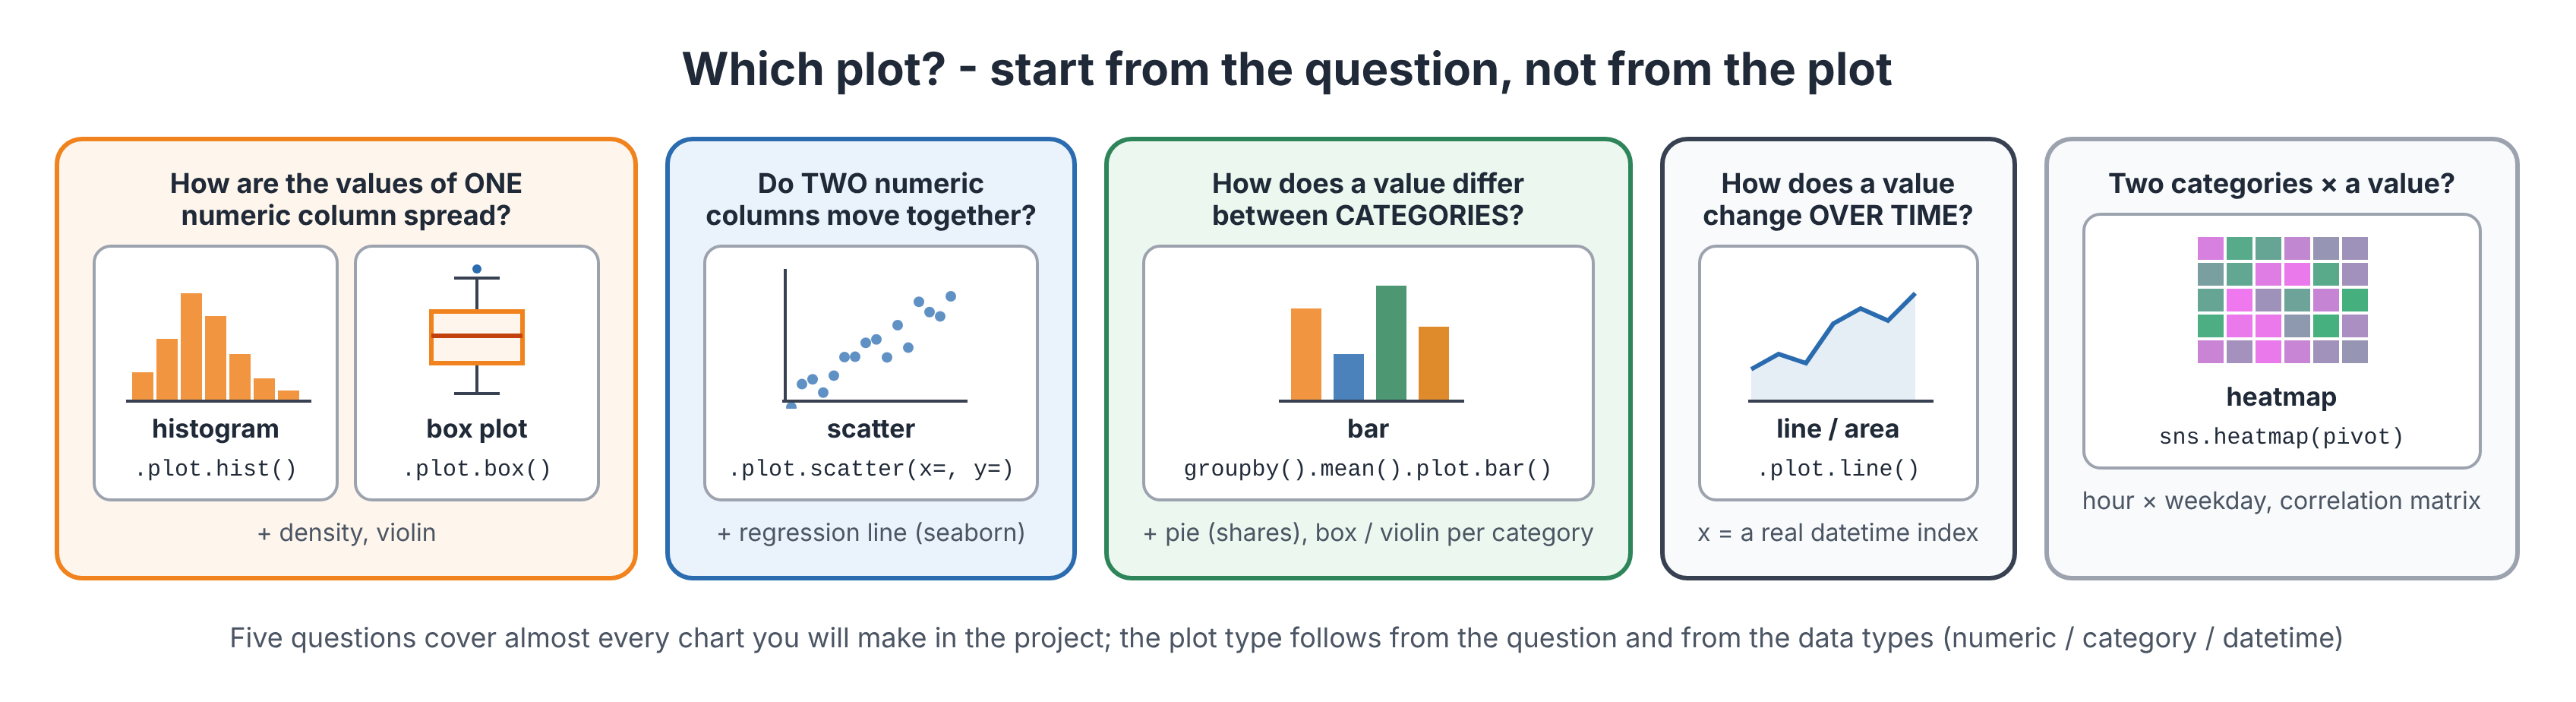

### Data Visualisation - matplotlib

__Matplotlib__ (first released in 2003) is the most popular library for data visualisation in Python.

It's extremely flexible, so you have almost full control on your plots.

pandas .plot for a quick look, matplotlib for full control, seaborn for statistical plots - all three draw with matplotlib
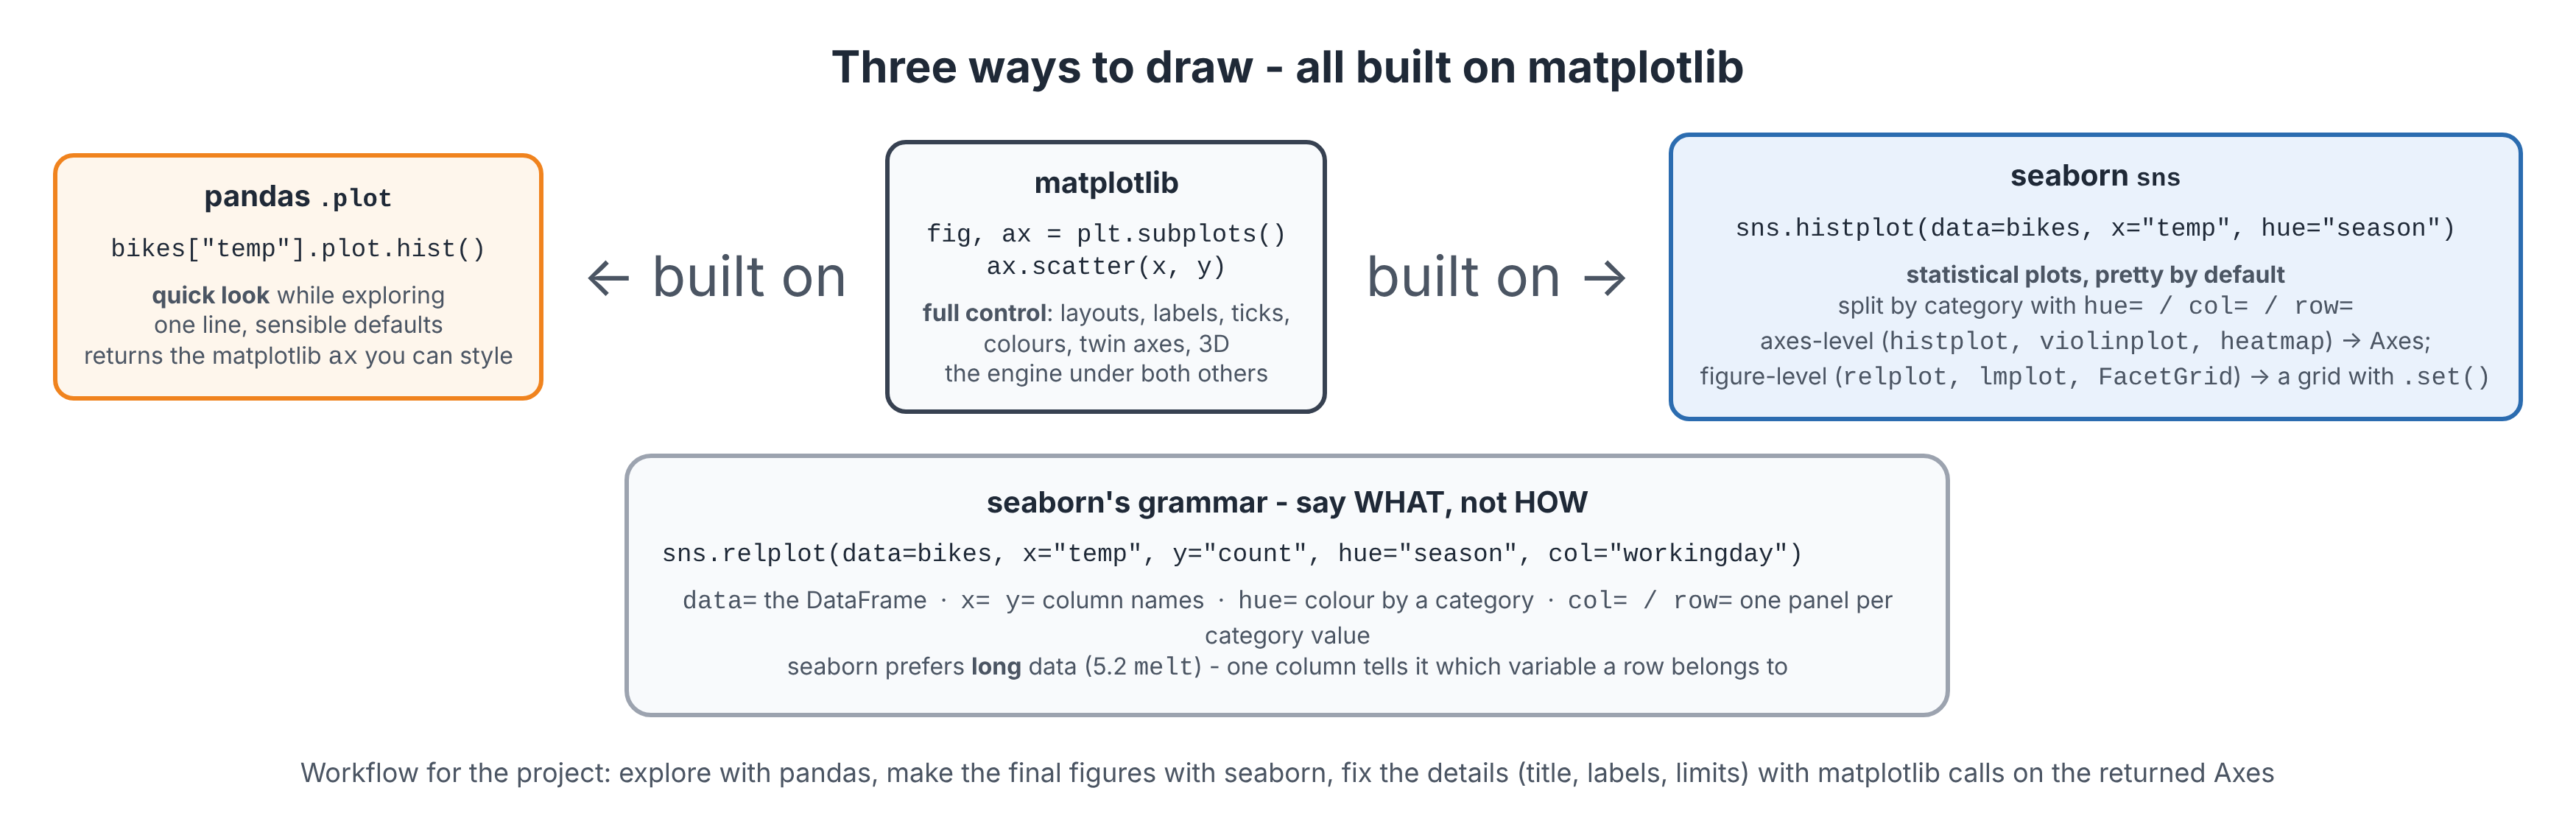

Three layers, draw with matplotlib underneath.
* pandas (one line, good enough while exploring)
* matplotlib (when the figure goes into a report and every label matters)
* seaborn (statistical plots and nicer defaults).

In [1]:
!pip install matplotlib

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

Note tha "magic" command that starts with %

`%matplotlib inline` tells Jupyter / Colab to show the plots **inside the notebook**, under the cell (it is the default in Colab, so you rarely need it, but it does no harm). `plt` is the conventional short name for `matplotlib.pyplot`, like `np` and `pd`.

## Data set - Bikes Sharing Demand

This presentation uses the popular Bikes Sharing Demand data set - please review the data set description in the presentation on Pandas.

In [3]:
import pandas as pd
import numpy as np

### Loading data set

The data set is split into two parts (training and testing data); we just combine them for presentation:

In [4]:
bikes = pd.read_csv("../content/bikes.csv")
bikes2 = pd.read_csv("../content/bikes_test.csv")
bikes = pd.concat([bikes,bikes2])
bikes.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3.0,13.0,16.0
1,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8.0,32.0,40.0
2,01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5.0,27.0,32.0
3,01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3.0,10.0,13.0
4,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0.0,1.0,1.0


### Data quality: what do we actually have?

`pd.concat` (5.2) stacked the two tables: 10 886 + 6 493 = 17 379 hourly rows, covering **every day** of 2011-2012 - but the rental columns are empty for the 6 493 test rows:

In [5]:
print(bikes.shape)
bikes.isna().sum()

(17379, 12)


,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,6493


This matters for every chart today: a plot of **temperature** uses all 17 379 hours, a plot of **rentals** uses only the 10 886 hours where `count` is known - pandas and seaborn drop the `NaN` rows silently and the chart does not tell you. To keep that visible we give the complete rows a name of their own and use it whenever rentals are involved (`bikes` itself stays as Dmitry built it):

In [6]:
bikes_known = bikes.dropna(subset=["count"])        # the 10 886 hours with known rentals
print(len(bikes), "hours in total,", len(bikes_known), "with rental counts")

17379 hours in total, 10886 with rental counts


### Defining data types

A proper definition of column types is necessary for correct data visualisation:

In [7]:
bikes["datetime"] = pd.to_datetime(bikes["datetime"], format='%d/%m/%Y %H:%M')
bikes["season"] = bikes["season"].astype('category')
bikes["weather"] = bikes["weather"].astype('category')
bikes["holiday"] = bikes["holiday"].astype('category')
bikes["workingday"] = bikes["workingday"].astype('category')
bikes["humidity"] = bikes["humidity"].astype(float)
bikes.dtypes

,0
datetime,datetime64[ns]
season,category
holiday,category
workingday,category
weather,category
temp,float64
atemp,float64
humidity,float64
windspeed,float64
casual,float64


In [8]:
bikes_known = bikes.dropna(subset=["count"])        # re-made from the typed table, so the dtypes match
bikes_known.dtypes["datetime"], bikes_known.dtypes["season"]

(dtype('<M8[ns]'),
 CategoricalDtype(categories=['fall', 'spring', 'summer', 'winter'], ordered=False, categories_dtype=object))

## matplotlib from Pandas

__Pandas__ seemless integrates several most frequently used __matplotlib__ plots:
* histograms
* bar plots
* scatters
* boxplots

## Histogram from Pandas

Histograms are used for visualising distribution of __continuous quantitative variables__ (like _temperature_) or __discrete quantitative variables__ with many unique values (like _count_)

* Single histogram

A histogram counts the values in bins; a density plot smooths every value with a kernel into a curve
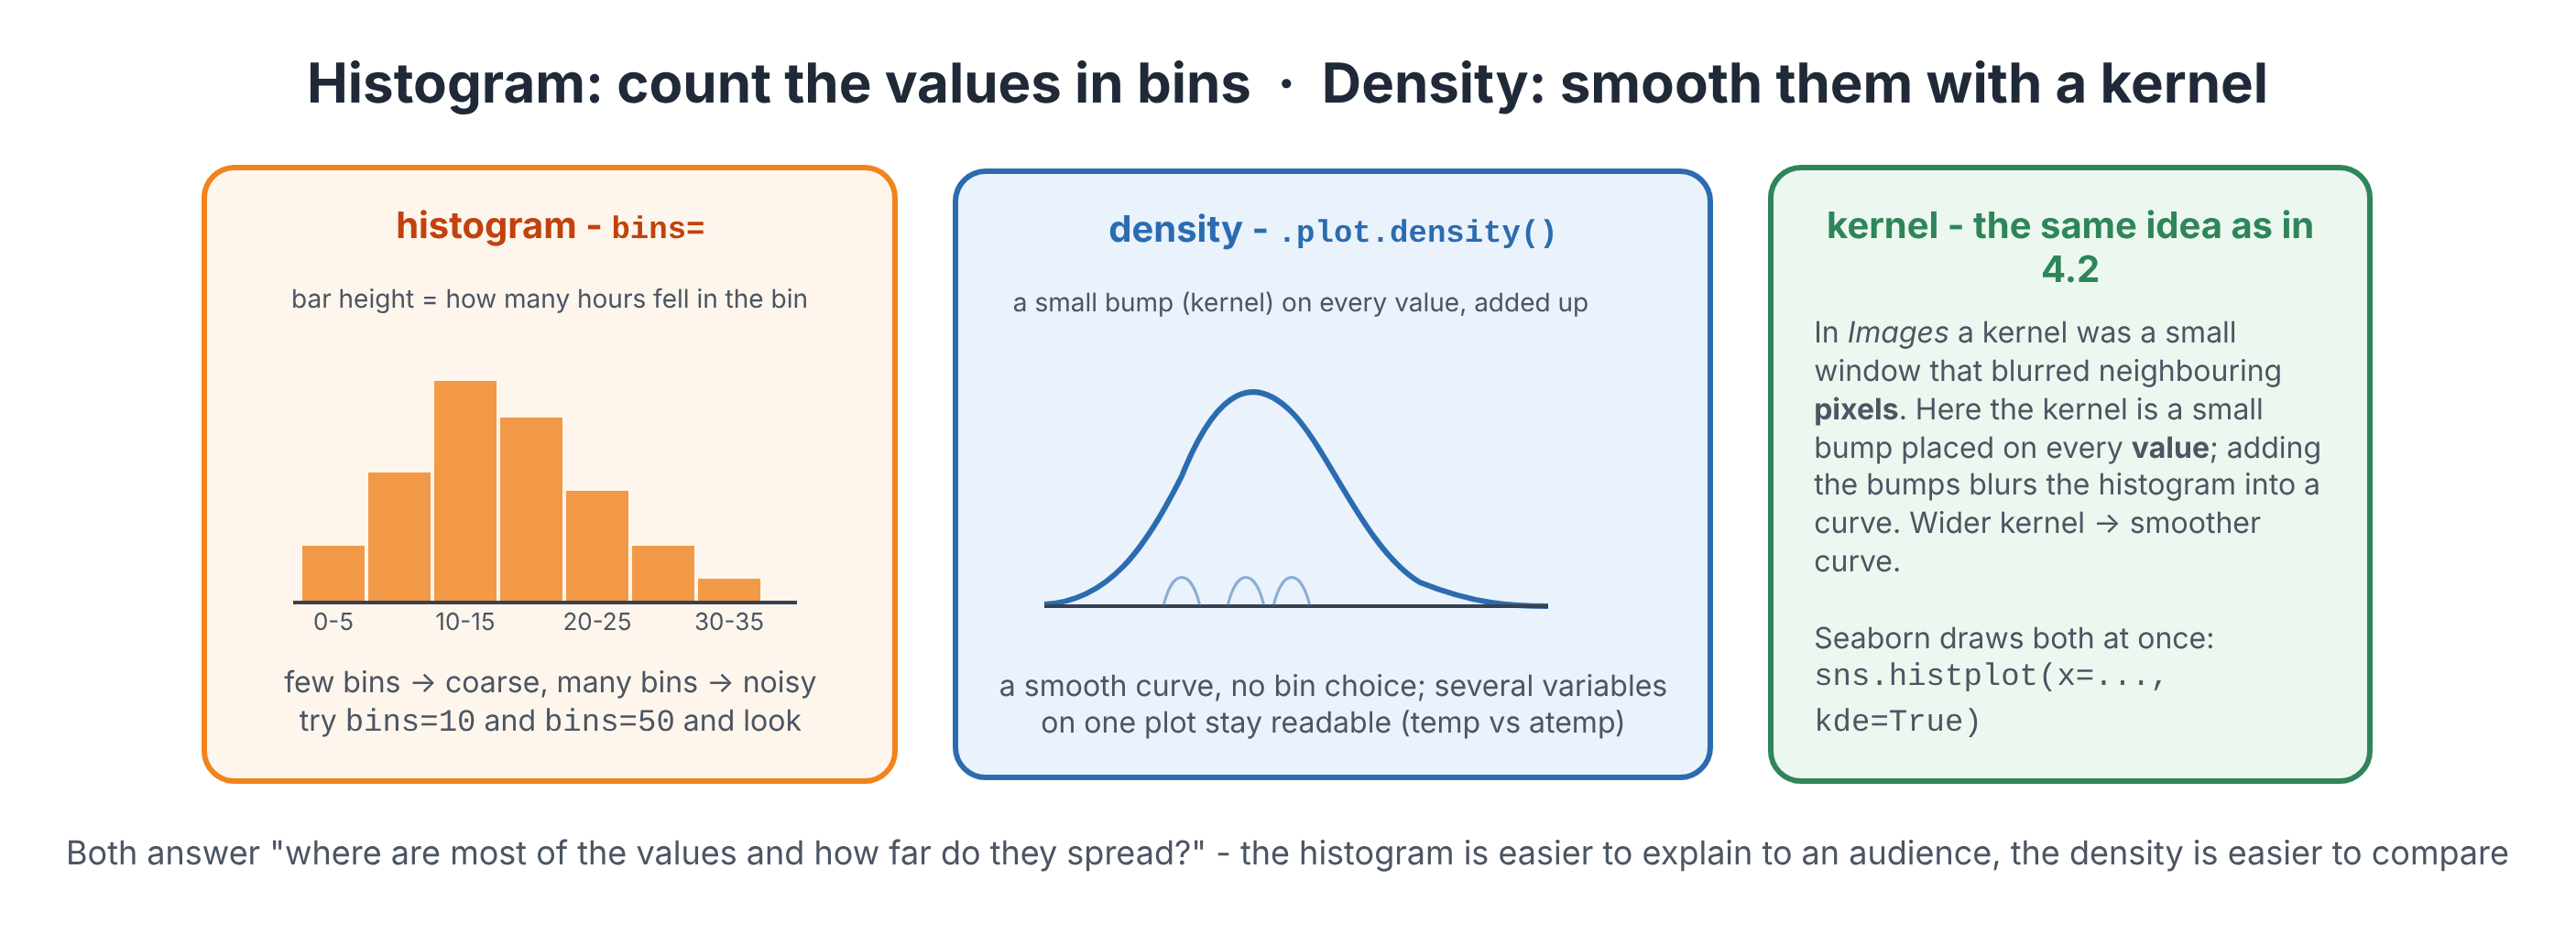

<Axes: ylabel='Frequency'>

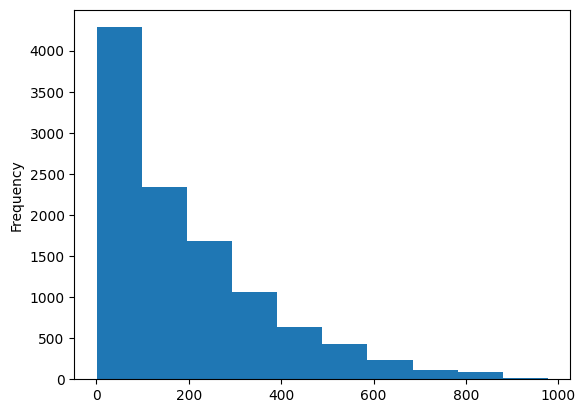

In [9]:
bikes["count"].plot.hist()

The first look at any numeric column: horizontal axis - the value (rentals per hour), vertical - how many hours fell into each bin. Most hours have fewer than 100 rentals and the tail stretches to almost 1 000 - a *right-skewed* distribution (5.1: mean 191 > median 145). Note: this histogram is built from the **10 886 known hours** - the 6 493 `NaN` rows were dropped without a message. The text `<Axes: ...>` above the plot is the returned object; end the line with `;` or assign it to hide the text.

### Histogram from Pandas

* Several histograms - separate axis

array([[<Axes: title={'center': 'temp'}>,
        <Axes: title={'center': 'atemp'}>]], dtype=object)

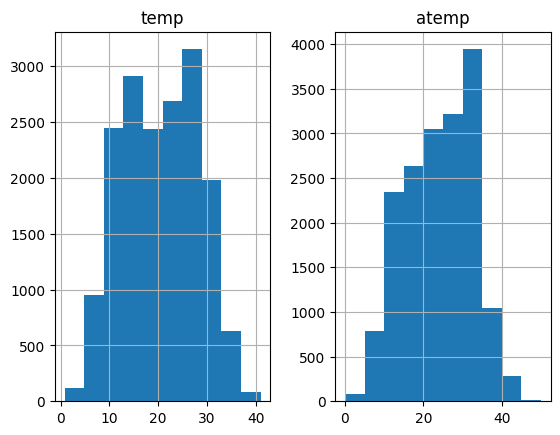

In [13]:
bikes[["temp", "atemp"]].hist()

### Histogram from Pandas

* Several histograms - shared axis

<Axes: ylabel='Frequency'>

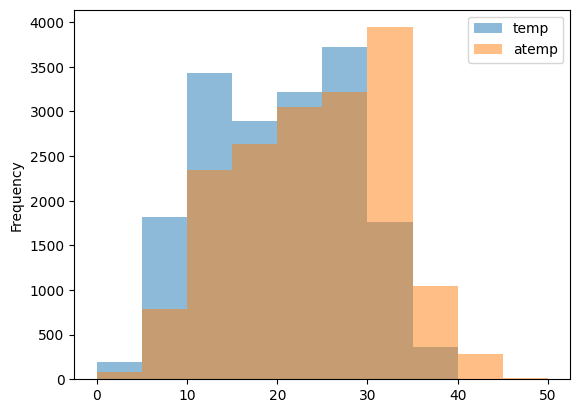

In [19]:
bikes[["temp", "atemp"]].plot.hist(bins=10, alpha=0.5)

Two forms: `df.hist()` → one panel **per column**; `df.plot.hist()` → all columns **in one panel**, where `alpha=0.5` (transparency) lets us see both. `bins=10` sets the number of bars - try 5 and 50 and see how the picture changes. (Temperature is known for all 17 379 hours, so these use the whole table.)

## Density plots from Pandas

Density plots provide more detailed information on distribution of quantitative variables by applying __kernels__.

Kernels are applied for every unique in the data set and provide weights for smoothing with neighbour values.

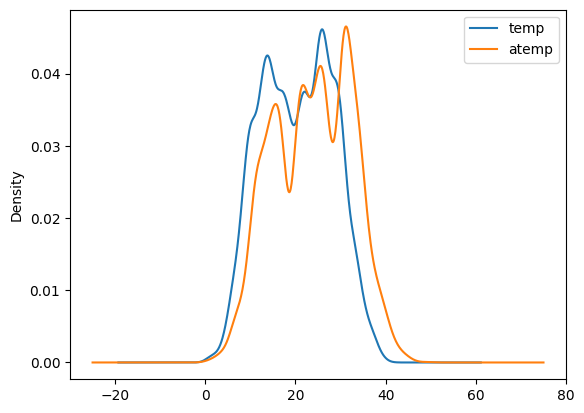

In [21]:
bikes[["temp", "atemp"]].plot.density();

Kernel density plots are much easier to read then several histograms on the same plot

* histogram shows actual counts of values in bins;
* density plot is a smoothed estimate of the same distribution - a small bump is placed on every value and the bumps are added up.
* The smooth curve is convenient for comparing several columns (`atemp` sits a few degrees to the right of `temp`), but smoothing can invent shape where there is none - a curve that continues below 0 °C, or a smooth hill over values that are really discrete. Use the density for comparing shapes, the histogram when the actual numbers matter. The vertical axis is a *density*: the area under each curve is 1.

## Box plots from Pandas

Box (box-and-whiskers) plots are used to represent most important desriptive statistics of a variable:

* Median - line in the middle)
* Quartiles (25% and 75%) - the box
* "Normal" deviation (different metrics) - the "whiskers"
* Outliers - circles ouside the whiskers

A box plot is describe() drawn: median, quartiles, whiskers, outliers
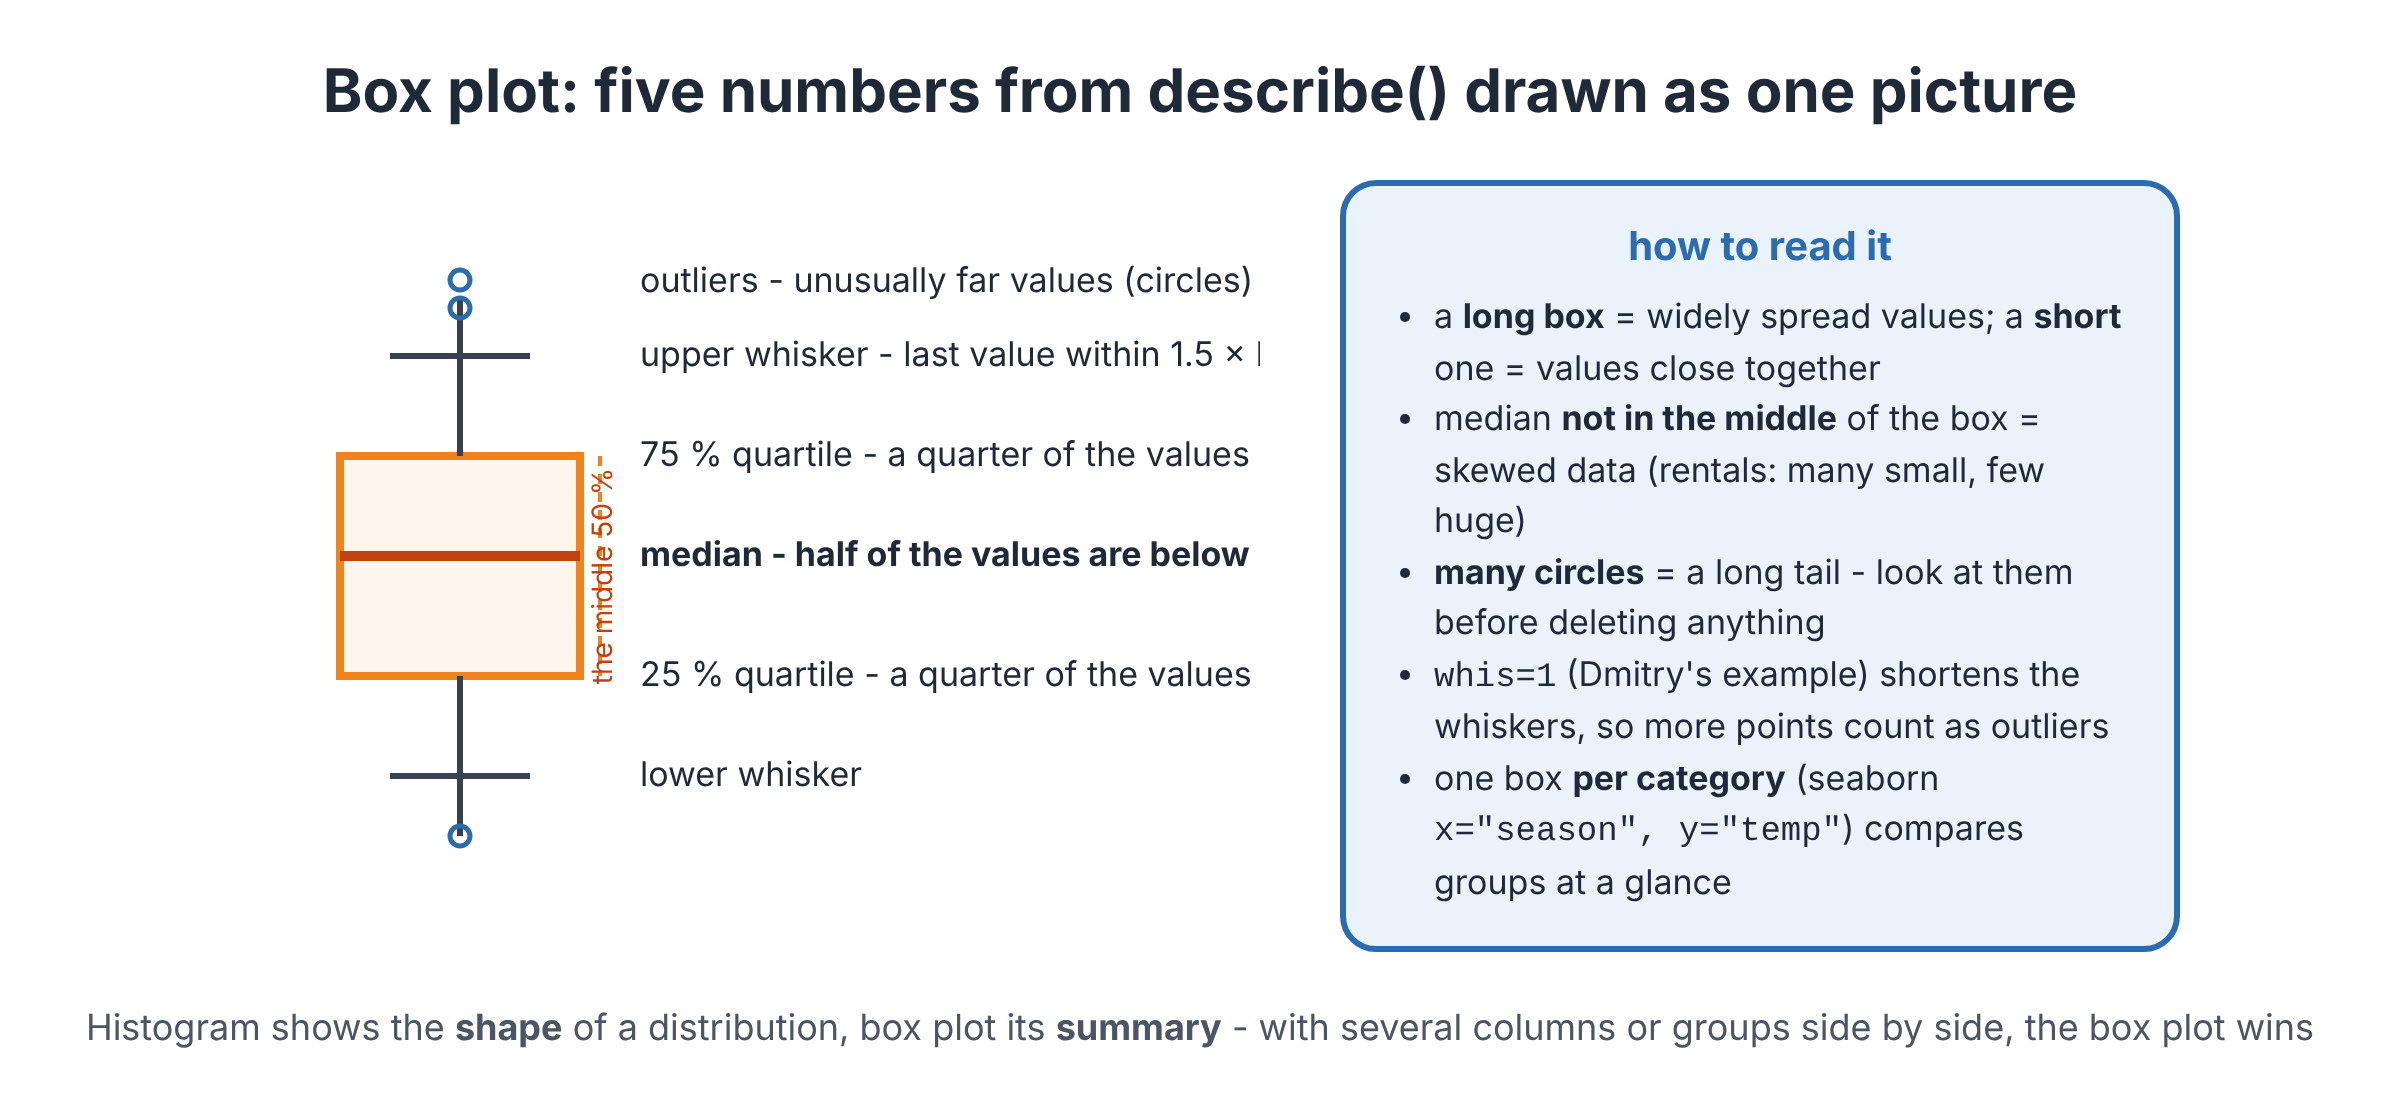

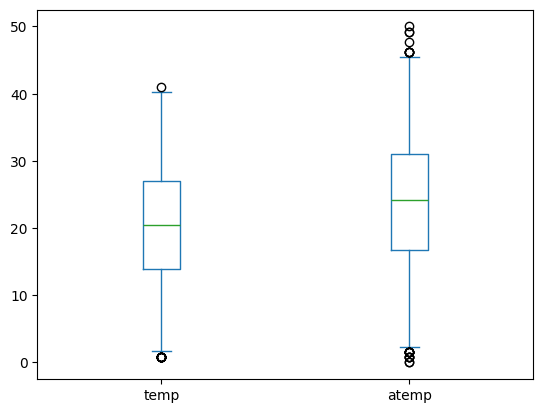

In [25]:
bikes[["temp", "atemp"]].plot.box(whis=1);

* One box per column, same scale - the quickest way to compare several numeric columns.
* `whis=1` sets the whisker length to 1 × the box height (default 1.5), so more points are shown as outlier circles;

## Scatter plots from Pandas

Scatter (XY) plots display all observations of two variables as points on the two-dimensional Cartesian plane and used to represent a relationship between variables:

<Axes: xlabel='temp', ylabel='count'>

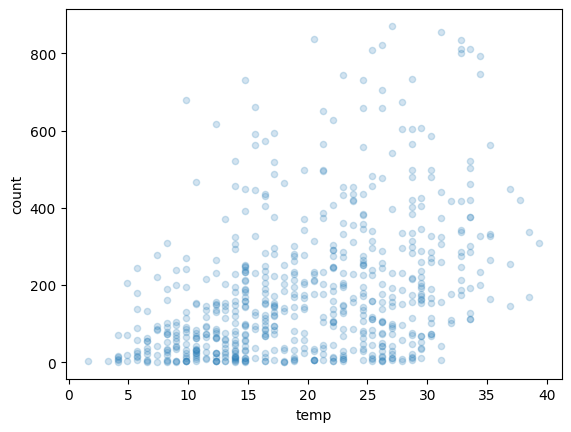

In [34]:
bikes.sample(1000).plot.scatter(x="temp", y="count",alpha=0.2)

Every point is one hour (of the 10 886 with known rentals): x its temperature, y its rentals.

The cloud rises to the right (the correlation of 0.39 from 5.1) and is widest in the middle - at 25 °C an hour can have 5 or 900 rentals, so temperature is only part of the story.

## Bar plots from Pandas

Bar plots represent categorical data with rectangular bars with heights that is proportional to the values which they represent.

In [35]:
bikes.groupby("season").agg({'count':'median'})

/tmp/ipykernel_1041/533408971.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bikes.groupby("season").agg({'count':'median'})


,count
season,
fall,195.0
spring,78.0
summer,172.0
winter,161.0


/tmp/ipykernel_1041/430604378.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bikes.groupby("season").agg({'count':'median'}).plot.bar()


<Axes: xlabel='season'>

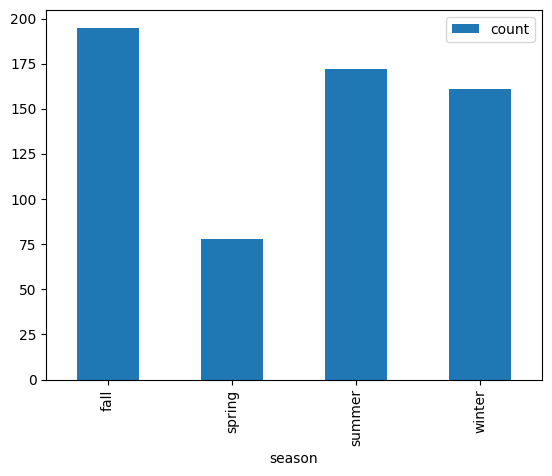

In [39]:
bikes.groupby("season").agg({'count':'median'}).plot.bar()

For bar chart: groupby → one number per category → .plot.

## Pie charts from Pandas

Pie charts are also used for representing categorical data, but are based on circle slices and usually better for representing relative values.

/tmp/ipykernel_1041/4106418707.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bikes.groupby("season").agg({'count':'median'}).plot.pie(y="count")


<Axes: ylabel='count'>

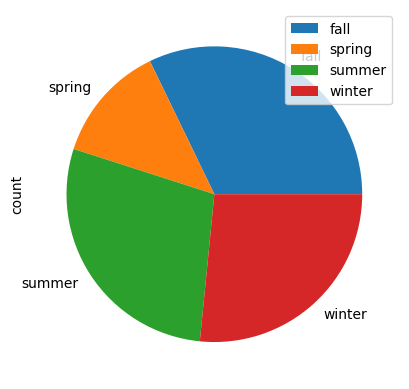

In [41]:
bikes.groupby("season").agg({'count':'median'}).plot.pie(y="count")

**Counterexample - do not use.** A pie shows **shares of a whole**, and the four medians are not shares of anything: a median of 195 rentals in fall is not "32 % of the rentals". The slices look reasonable, which is exactly what makes this chart dangerous - the reader believes it. A *valid* pie of the same data answers the question *"which share of all rentals happened in each season?"* - the **totals**, which do add up to 100 %:

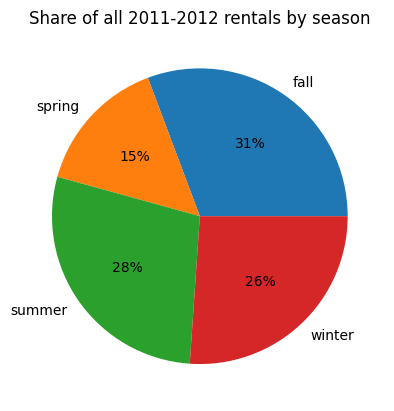

In [42]:
totals = bikes_known.groupby("season", observed=True)["count"].sum()
ax = totals.plot.pie(autopct="%.0f%%", ylabel="")
ax.set_title("Share of all 2011-2012 rentals by season");

Even then, with more than 4-5 slices or slices of similar size a bar chart is easier to compare; pies are for "one big part vs. the rest".

## Line plots from Pandas

Line plots represent a series of values, ordered by the numeric scale

<Axes: xlabel='datetime'>

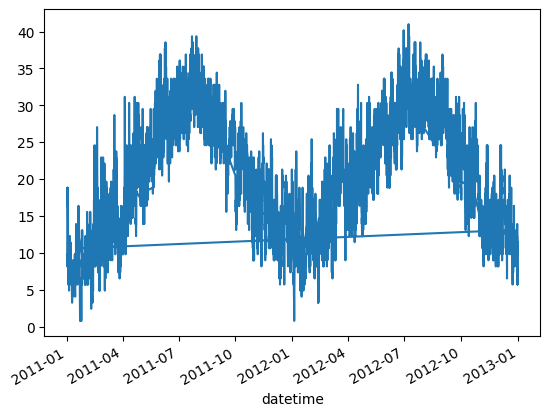

In [43]:
bikes.set_index("datetime")['temp'].plot.line()

A line needs an **ordered** x-axis - time, or a numeric scale. `set_index("datetime")` puts the real dates on the x-axis (that is why we converted the type). Two yearly cycles are visible; the dense "hair" is the day-night temperature swing of 17 000 hourly points. Smoothing to weekly means (appendix, *Formatter*) makes the trend cleaner.

## Area plots from Pandas

Area plots are line plots with filled area underneath. Frequently used in a stacked form for representing dinamics of components (e.g., registered and casual bike rentals).

<Axes: >

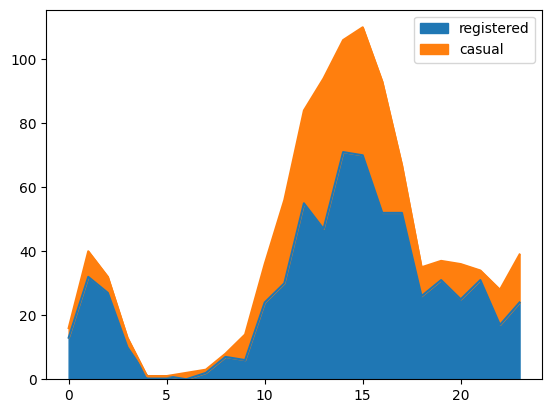

In [44]:
first_day = min(bikes["datetime"].dt.date)
bikes.loc[bikes['datetime'].dt.date==first_day,["registered","casual"]].plot.area()

Reading the two lines: `first_day` is the earliest date in the data (1 January 2011); the mask keeps the 24 hours of that day; the area plot **stacks** `casual` on top of `registered`, so the upper edge is the total. On a holiday morning registered users dominate; casual riders appear in the afternoon. (The x-axis shows the row position 0-23 = the hour, because the index is still the default one.)

### YOUR TURN 1: a first look with pandas plots

Use `bikes` for weather columns and `bikes_known` whenever rentals are involved.

1. Draw a histogram of `windspeed` with `bins=20`. Is the distribution symmetric or skewed? Where is the most common wind speed?
2. Draw a box plot of `casual` and `registered` side by side. Which group has more outliers, and what does that mean in words?
3. Draw a scatter of `humidity` (x) against `count` (y) with `alpha=0.1`. Is the relationship positive or negative?
4. A bar chart of the **mean** `count` per `weather` category (1 clear … 4 heavy rain). Write one sentence that the chart supports - and say how many hours are behind the last bar (`value_counts()`).

*Optional:* a line plot of `humidity` over time for the first day (`first_day` mask), and the same with `casual` and `registered` as two lines (`.plot.line()` instead of `.plot.area()`).

In [ ]:
# YOUR CODE HERE:

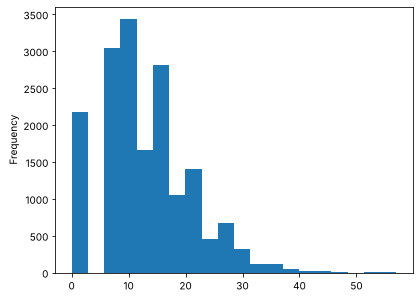

In [ ]:
# 1.  -> right-skewed; most hours have 7-15 km/h, a few very windy hours up to 57 (all 17 379 hours)
bikes["windspeed"].plot.hist(bins=20);

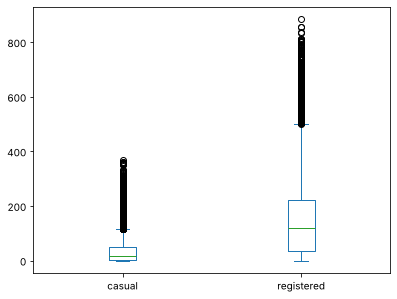

In [ ]:
# 2.  -> registered: many high outliers (busy commute hours); casual: a long tail too, but lower values overall
bikes_known[["casual", "registered"]].plot.box();

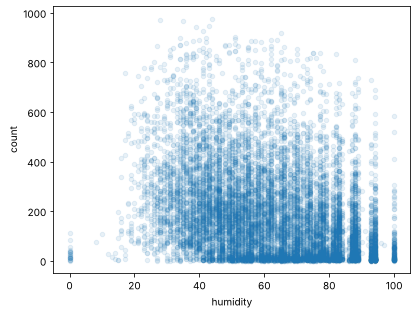

In [ ]:
# 3.  -> negative: humid hours tend to have fewer rentals (correlation -0.32 in 5.1)
bikes_known.plot.scatter(x="humidity", y="count", alpha=0.1);

weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


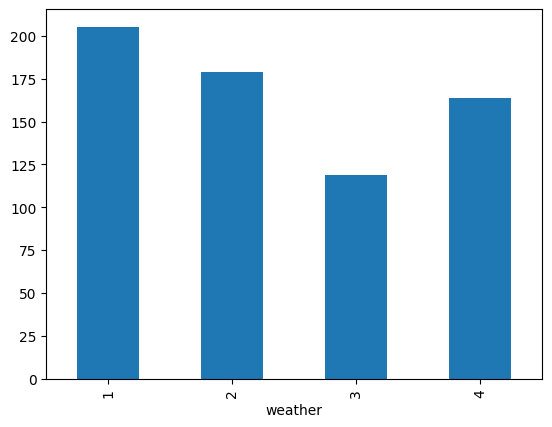

In [45]:
# 4.  -> "Rentals fall as the weather gets worse; the heavy-rain bar rests on a single hour and should not be read."
bikes_known.groupby("weather", observed=True)["count"].mean().plot.bar();
print(bikes_known["weather"].value_counts())

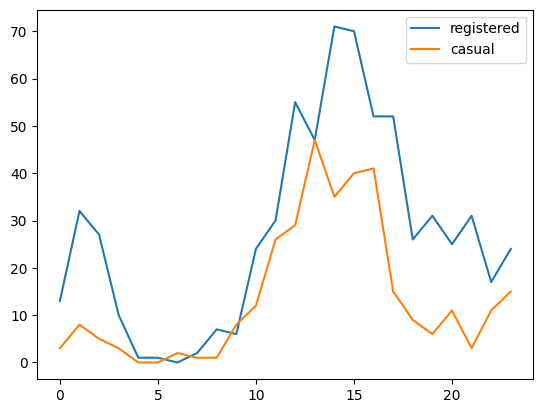

In [46]:
# optional
bikes.loc[bikes['datetime'].dt.date==first_day, ["registered", "casual"]].plot.line();

## matplotlib

Although Pandas plot functions are convenient, constructing figures by matplotlib from scratch gives you the full control over the results.

Frequently used feature that require direct usage of __matplotlib__:
* Advanced layouts
* Full control over presentation

### Anatomy of _matplotlib_ figure

<img width="700" src="https://matplotlib.org/3.5.0/_images/sphx_glr_anatomy_001_2_0x.png"/>

One Figure (the canvas) holds one or more Axes (plot areas); title, axis labels, ticks, legend and grid belong to the Axes
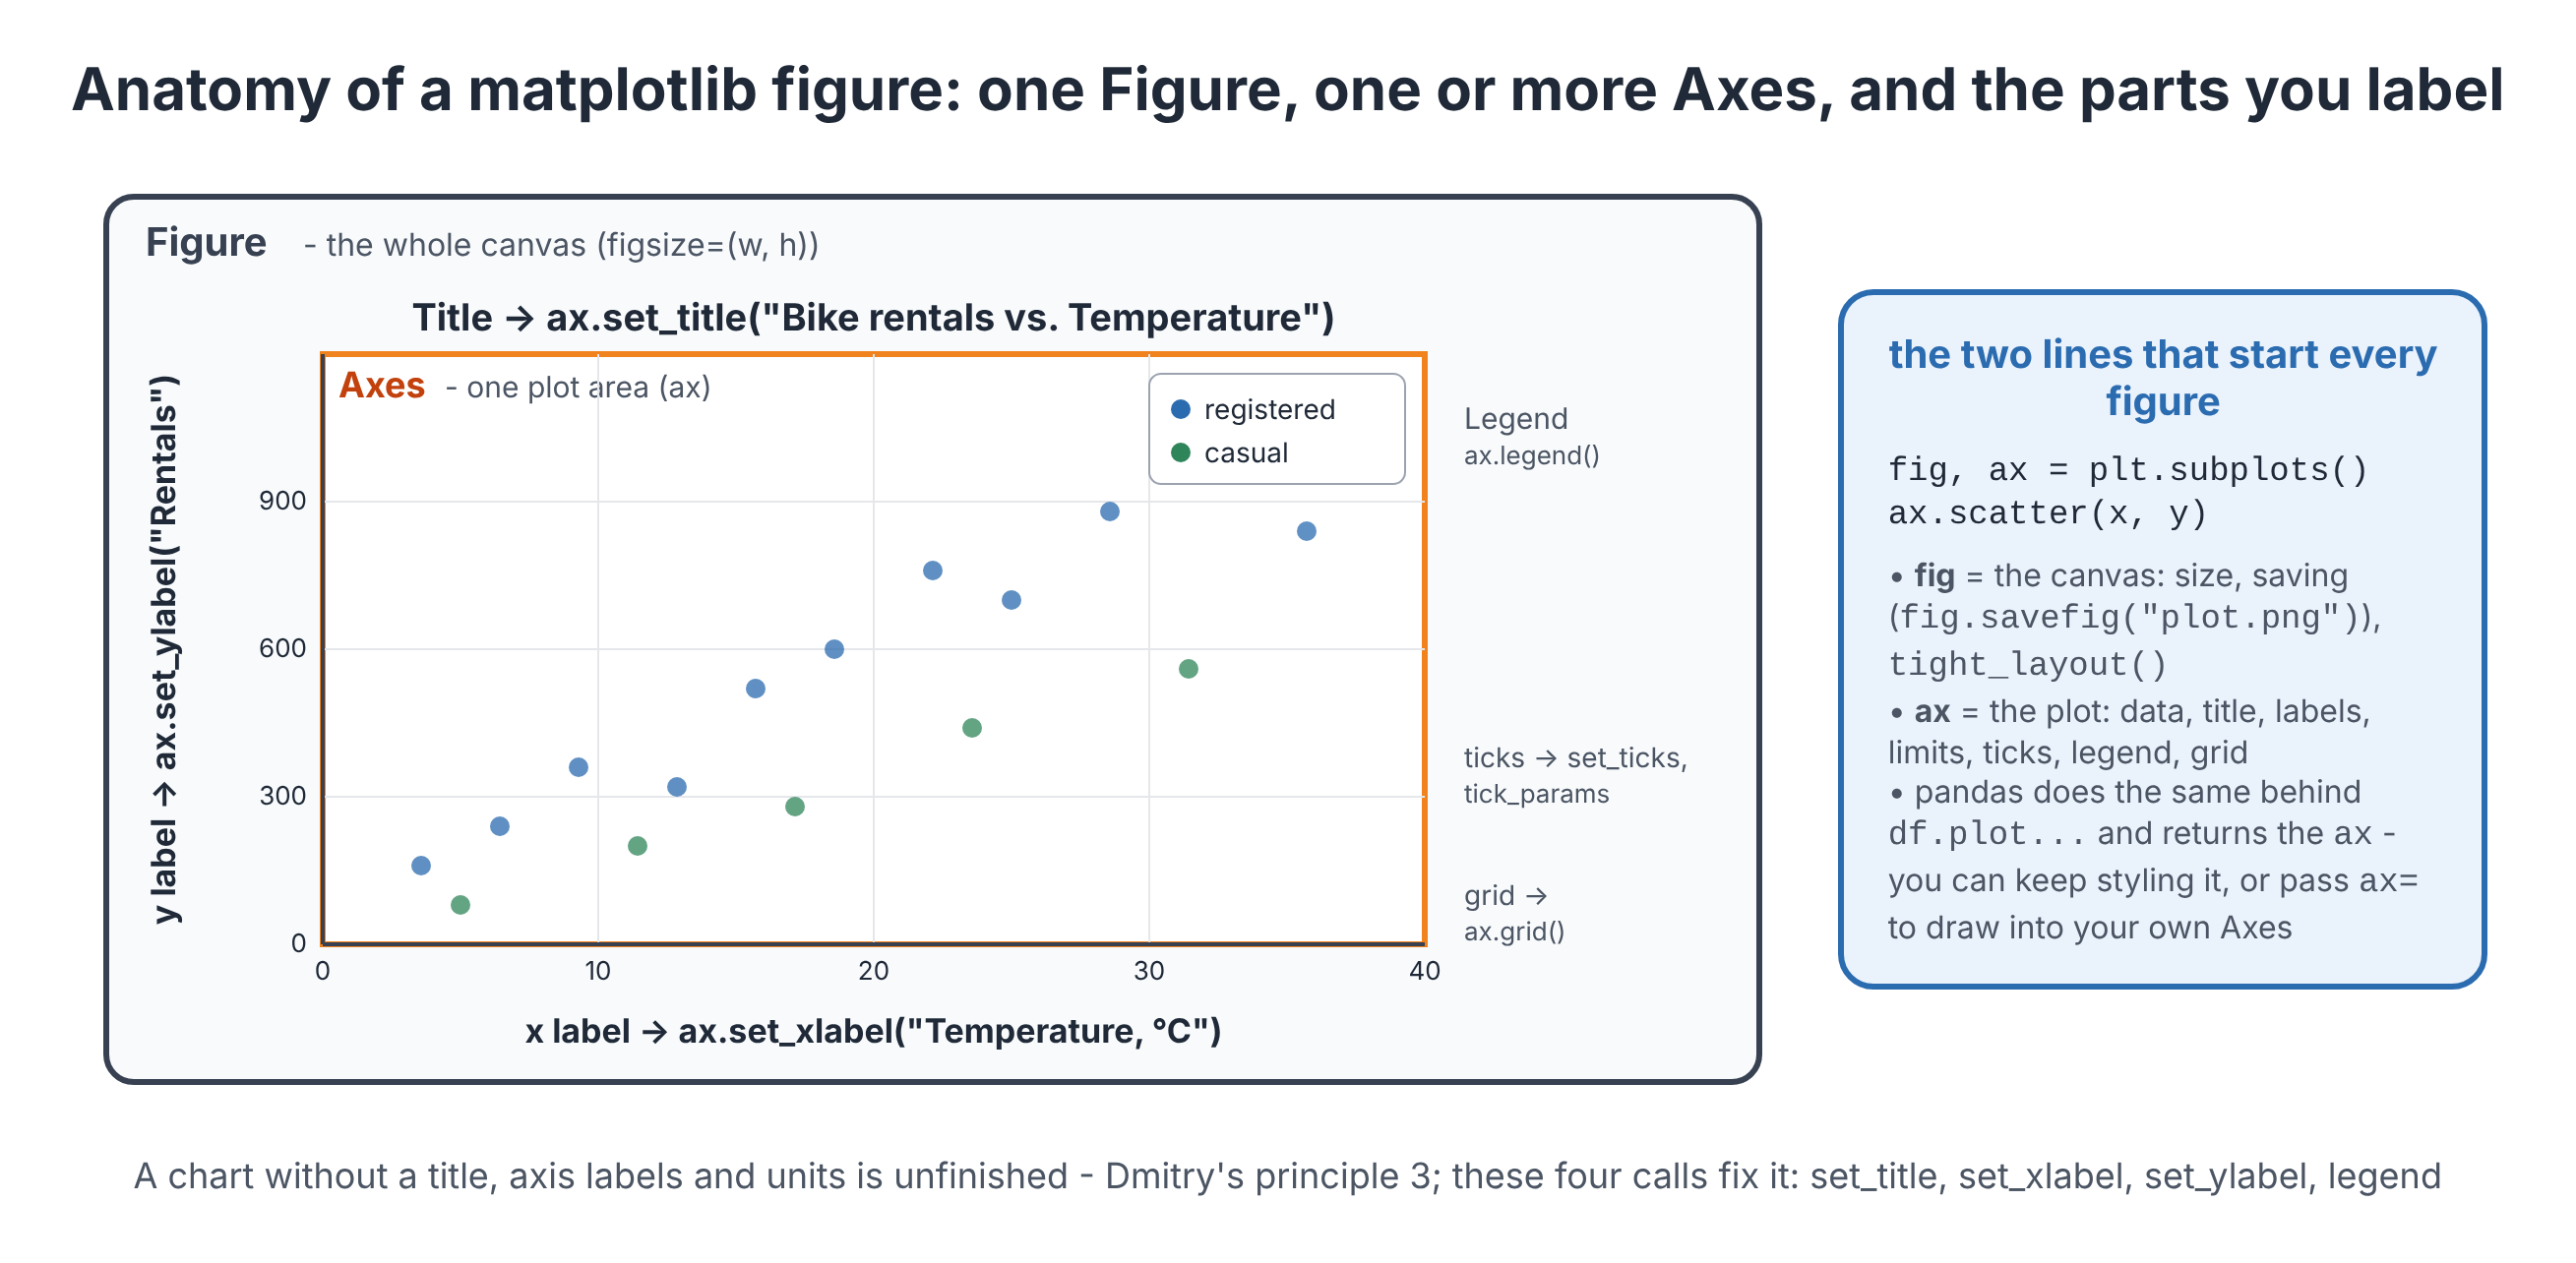

* **Figure** is the whole canvas (its size, saving to a file),
* **Axes** is one plot area with its own title, labels and ticks. A figure can hold several Axes - that is how we get several plots in one picture.
* `plt.subplots()` creates both and hands them back as `figure, axis`.

### Matplotlib figure: example

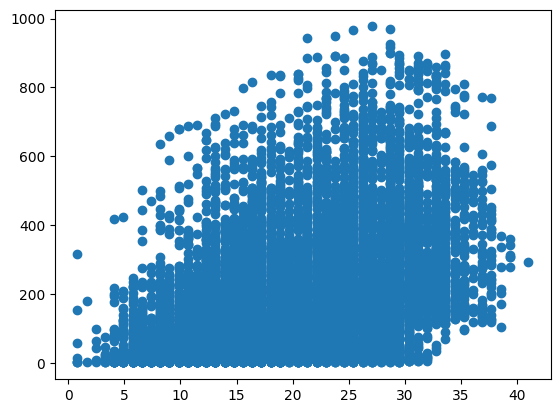

In [50]:
figure, axis = plt.subplots()
axis.scatter(x=bikes['temp'], y=bikes['count'])
plt.show()

The same scatter as `bikes.plot.scatter(...)`, written in three explicit lines: create figure + axes, draw on the axes, show. From now on everything we want to change - a title, a label, a second plot - is a method call on `axis`.

### Advanced layout: subplots

plt.subplots(rows, cols) returns a grid of Axes; address them by index, flatten() turns the grid into a simple list
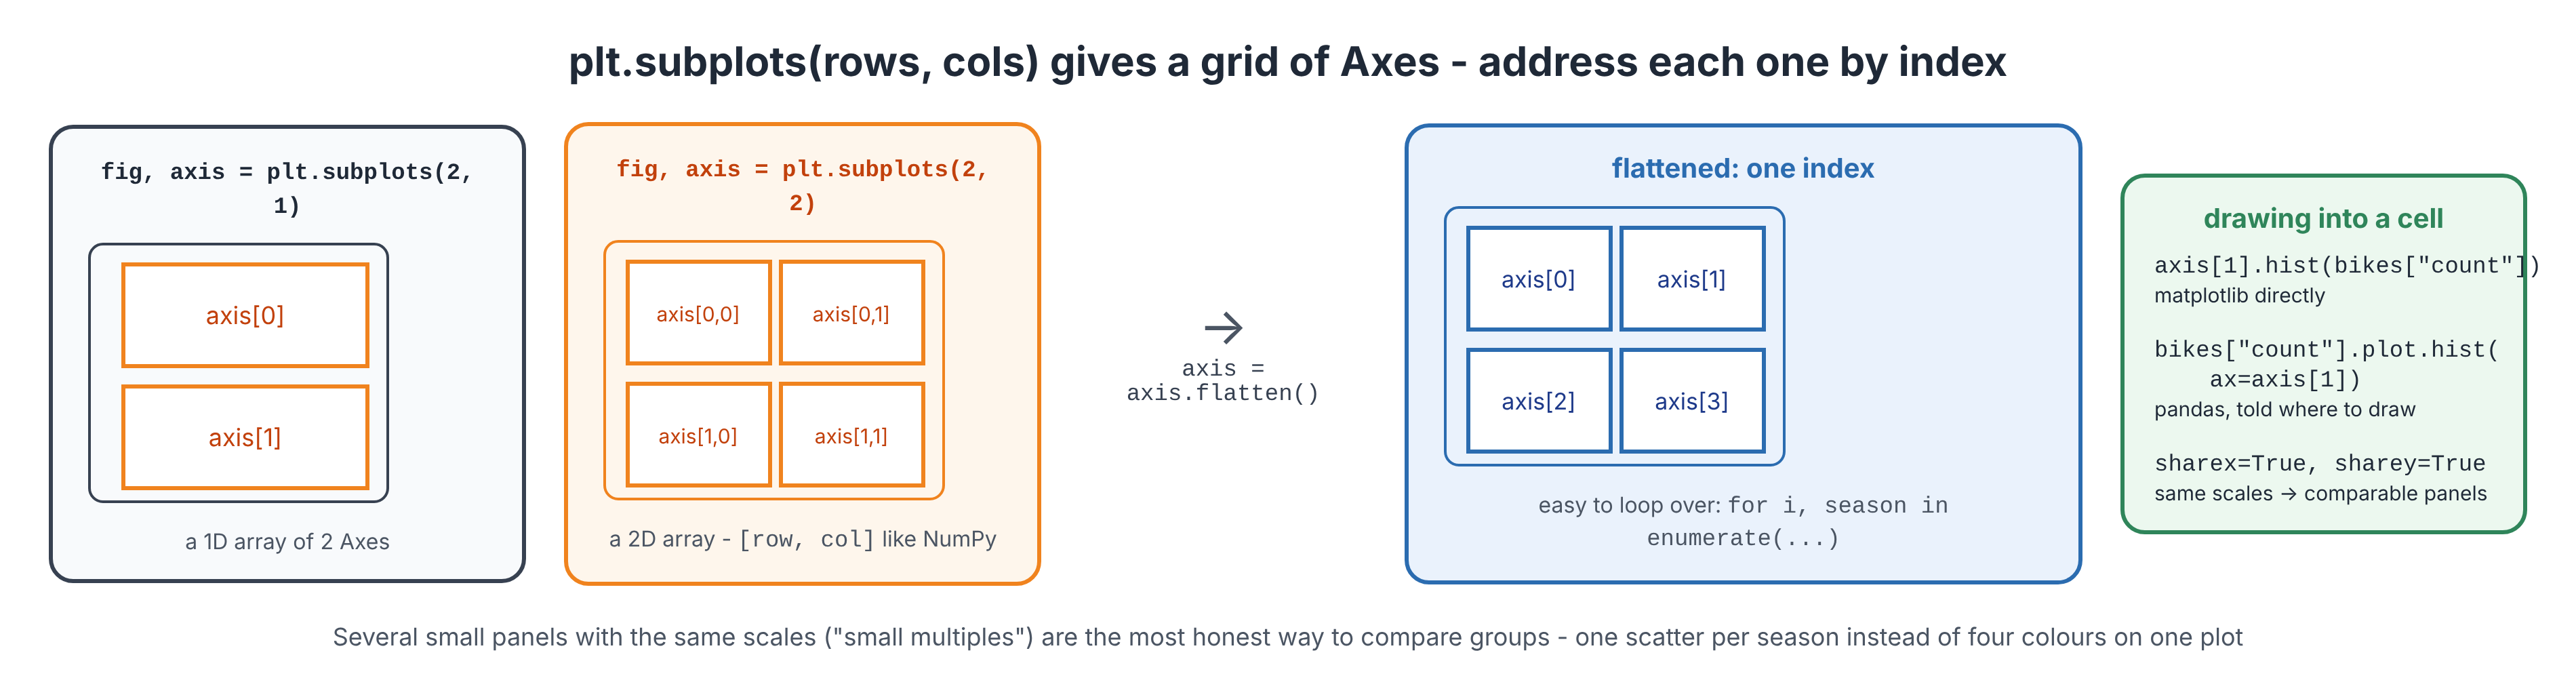

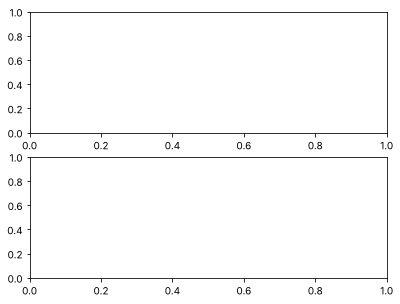

In [ ]:
figure, axis = plt.subplots(2, 1)

In [ ]:
print(axis)

[<Axes: > <Axes: >]


`subplots(2, 1)` - 2 rows, 1 column: an empty figure with two Axes, returned as a NumPy **array** (4.1!) - `axis[0]` is the top one, `axis[1]` the bottom one.

### Advanced layout: plotting on different axis

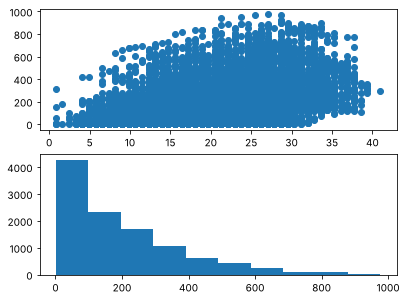

In [ ]:
figure, axis = plt.subplots(2, 1)
axis[0].scatter(x=bikes['temp'], y=bikes['count'])
axis[1].hist(bikes['count'])
plt.show()

### Advanced layout: using axis by Pandas

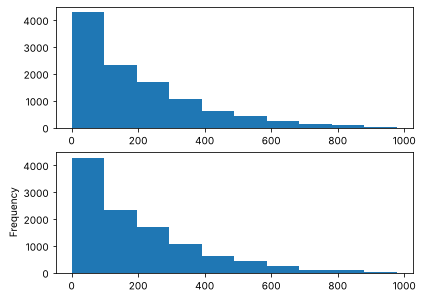

In [ ]:
figure, axis = plt.subplots(2, 1)
axis[0].hist(bikes['count'])
bikes['count'].plot.hist(ax=axis[1])
plt.show()

Two ways to draw into a cell of the grid: matplotlib directly (`axis[0].hist(...)`) or pandas with `ax=axis[1]` - "draw your plot *there*". Both give the same histogram; the pandas one adds the axis label for free. Mixing them is normal. (Both silently ignore the `NaN` rows of the test part - neither tells you that only 10 886 of the 17 379 hours are drawn. One more reason to plot rentals from `bikes_known`.)

### Advanced layout: grid

/tmp/ipykernel_1041/3446828420.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bikes.groupby("season").agg({'count':'median'}).plot.density(ax=axis[2])
/tmp/ipykernel_1041/3446828420.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bikes.groupby("season").agg({'count':'median'}).plot.bar(ax=axis[3])


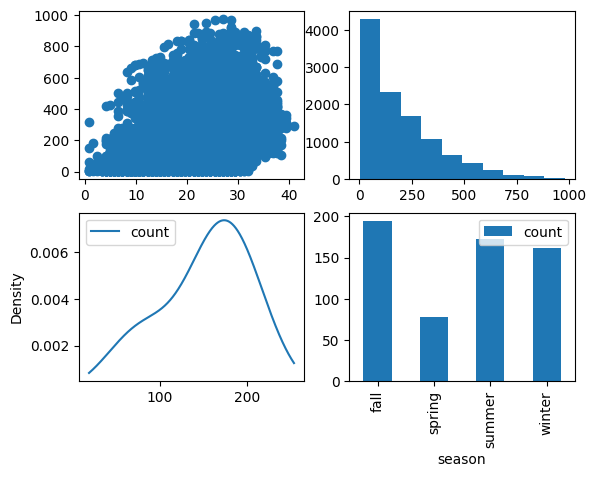

In [51]:
figure, axis = plt.subplots(2, 2)
axis = axis.flatten()
axis[0].scatter(x=bikes['temp'], y=bikes['count'])
axis[1].hist(bikes['count'])
bikes.groupby("season").agg({'count':'median'}).plot.density(ax=axis[2])
bikes.groupby("season").agg({'count':'median'}).plot.bar(ax=axis[3])
plt.show()

A 2 × 2 grid is a 2D array of Axes; `axis.flatten()` (4.1) turns it into a flat list so we can count 0, 1, 2, 3 instead of `[0, 0]`, `[0, 1]` ... Four plots, one figure - a **layout** demonstration. Panel 2 (bottom left) is deliberately a bad chart: a density estimated from **four** medians says nothing about the data. The meaningful plot for that cell is a comparison of the rentals *per season* - and the labels need `tight_layout()`:

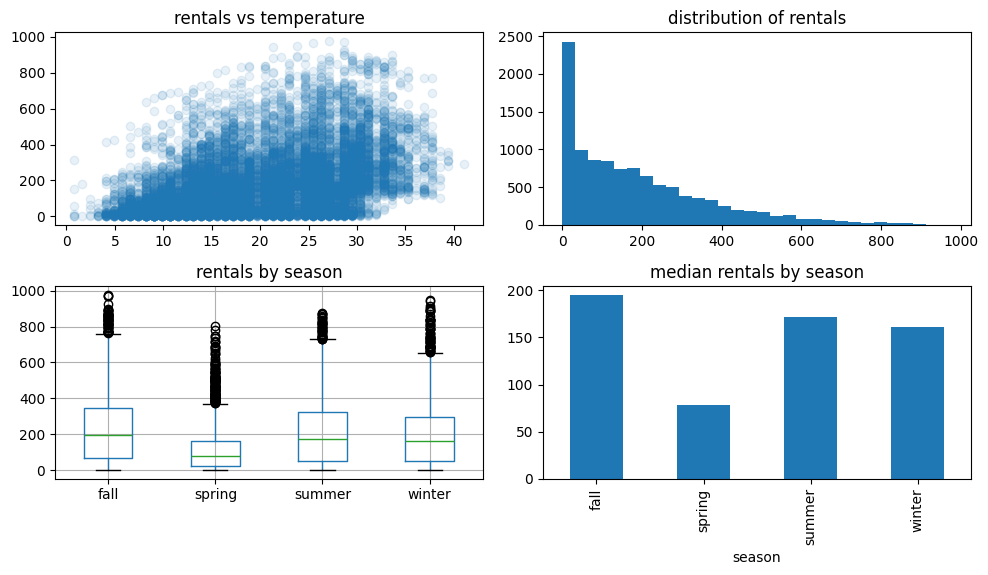

In [52]:
figure, axis = plt.subplots(2, 2, figsize=(10, 6))
axis = axis.flatten()
axis[0].scatter(x=bikes_known['temp'], y=bikes_known['count'], alpha=0.1); axis[0].set_title("rentals vs temperature")
axis[1].hist(bikes_known['count'], bins=30);                               axis[1].set_title("distribution of rentals")
bikes_known.boxplot(column="count", by="season", ax=axis[2]);             axis[2].set_title("rentals by season"); axis[2].set_xlabel("")
medians.plot.bar(ax=axis[3]);                                              axis[3].set_title("median rentals by season")
figure.suptitle("")                                   # pandas' boxplot adds a figure title - remove it
figure.tight_layout(); plt.show()

### Advanced layout: grids

Problem: plot count/temperature scatters for different seasons

In [53]:
bikes['season'].unique()

['spring', 'summer', 'fall', 'winter']
Categories (4, object): ['fall', 'spring', 'summer', 'winter']

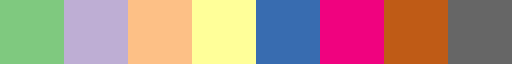

In [54]:
plt.cm.Accent

Two preparations: the list of seasons to loop over, and a **colormap** - a ready-made set of colours (`plt.cm.Accent` has 8); `plt.cm.Accent.colors[i]` picks the i-th one. Many colormaps exist (`viridis`, `coolwarm`, ...); for categories pick a *qualitative* one like `Accent` or `tab10`.

### Advanced layout: grids

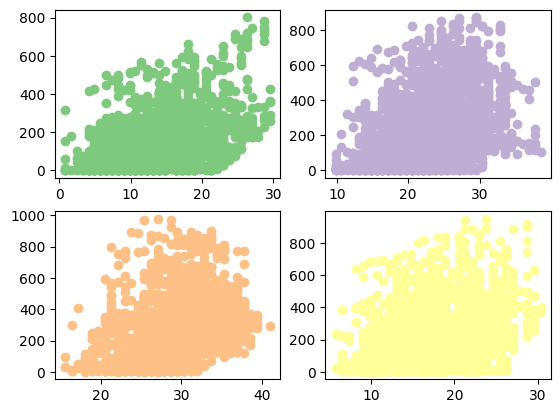

In [55]:
figure, axis = plt.subplots(2, 2)
axis = axis.flatten()
i = 0
for season in bikes['season'].unique():
    axis[i].scatter(x=bikes.loc[bikes['season']==season,'temp'],
                    y=bikes.loc[bikes['season']==season,'count'],
                    color=plt.cm.Accent.colors[i])
    i+=1
plt.show()

A `for` loop (week 2) over the four seasons: filter the rows of one season with a mask (5.1), draw them on panel `i`, move to the next panel. This "one panel per group" pattern - **small multiples** - is the most honest way to compare groups, and the loop is the same for 4 or 40 groups.

### Advanced layout: shared axes

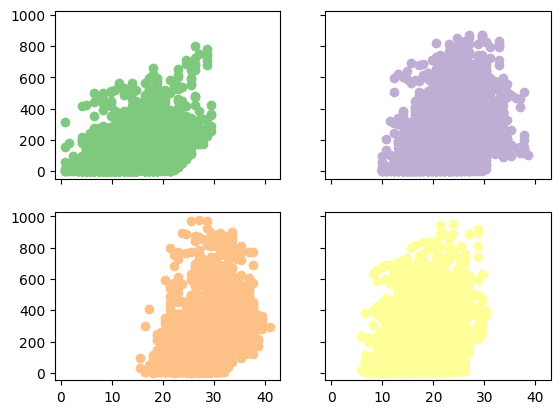

In [56]:
figure, axis = plt.subplots(2, 2, sharex=True, sharey=True)
axis = axis.flatten()
i = 0
for season in bikes['season'].unique():
    axis[i].scatter(x=bikes.loc[bikes['season']==season,'temp'],
                    y=bikes.loc[bikes['season']==season,'count'],
                    color=plt.cm.Accent.colors[i])
    i+=1
plt.show()

Compare with the previous figure: there each panel had its **own** scale, so spring (0-30 °C) looked as wide as fall (15-40 °C). `sharex=True, sharey=True` gives all panels the same axes - now the shift of the clouds to the right from spring to fall is visible, and the inner tick labels disappear. Panels that are meant to be compared must share scales.

### Full control: adding titles and labels

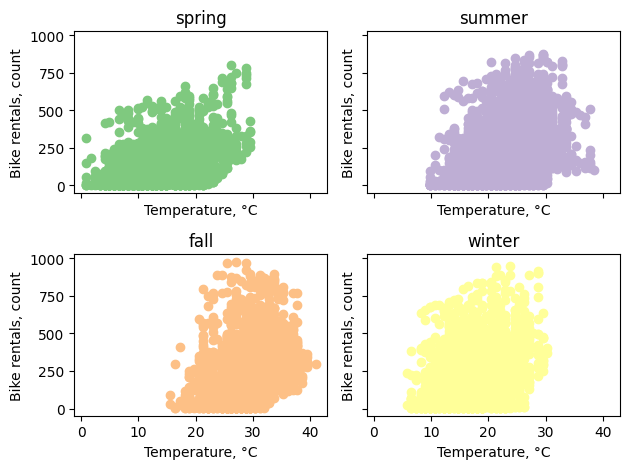

In [58]:
deg = u'\N{DEGREE SIGN}'

figure, axis = plt.subplots(2, 2, sharex=True, sharey=True)
axis = axis.flatten()
i = 0
for season in bikes['season'].unique():
    axis[i].scatter(x=bikes.loc[bikes['season']==season,'temp'],
                    y=bikes.loc[bikes['season']==season,'count'],
                    color=plt.cm.Accent.colors[i])
    axis[i].set_title(season)
    axis[i].set_xlabel("Temperature, "+deg+"C")
    axis[i].set_ylabel("Bike rentals, count")
    i+=1
figure.tight_layout()
plt.show()

* very panel has a **title** (the season) and both axes have **names with units** (`deg` is the ° character).
* `figure.tight_layout()` spreads the panels so nothing overlaps.
* These three calls - `set_title`, `set_xlabel`, `set_ylabel` - are the minimum for any figure

### Full control: plot attributes

In [59]:
def make_plot():
    figure, axis = plt.subplots(figsize=(12, 5))
    for season in bikes['season'].unique():
        axis.scatter(x=bikes.loc[bikes['season']==season,'temp'],
                     y=bikes.loc[bikes['season']==season,'count'],
                     label=season, cmap=plt.cm.Accent)
    axis.set_title("Bike rentals vs. Temperature") #Title
    axis.set_xlabel("Temperature, "+deg+"C") # X axis' label
    axis.set_ylabel("Bike rentals, count") # Y axis' label
    axis.set_ylim([0,1200]) # Y axis' limits
    axis.set_xlim([0,45]) # X axis' limits
    startx, endx = axis.get_xlim()
    start, end = axis.get_ylim()
    axis.xaxis.set_ticks(np.arange(startx, endx, 10)) # Sequence of X ticks
    axis.yaxis.set_ticks(np.arange(start, end, 400)) # Sequence of Y ticks

    axis.tick_params(axis='x',
                     labelrotation=45,
                     color='red',
                     labelcolor='blue',
                     grid_color="red",
                     grid_alpha=0.5) # X axis' tick format
    axis.get_yticklabels()[1].set_color('red') # Individual X axis' tick format
    axis.legend(loc='upper left'); # Legend
    plt.grid() # Show grid

### Full control: plot attributes

/tmp/ipykernel_1041/3616124791.py:4: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  axis.scatter(x=bikes.loc[bikes['season']==season,'temp'],


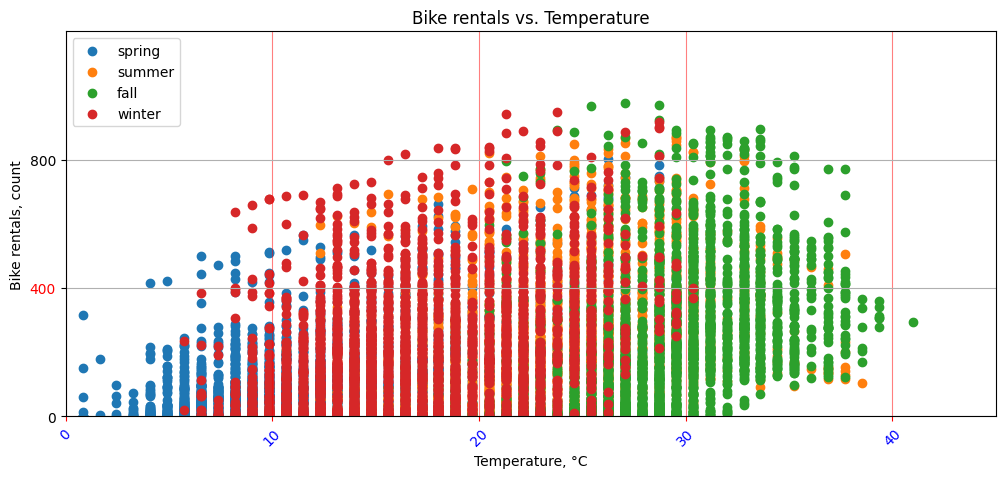

In [60]:
make_plot()
plt.show()

A **catalogue cell** - every commented line changes one thing: figure size, title, labels, axis limits, where the ticks are, how the tick labels look (rotation, colour), the legend position, the grid.

### YOUR TURN 2: one figure for a report

Build one figure with `plt.subplots(1, 2, figsize=(12, 4))`, using `bikes_known`:

1. Left panel: a histogram of `temp` with 20 bins; title *"Temperature distribution"*, x-label with the unit.
2. Right panel: a scatter of `temp` vs `count` with `alpha=0.1`; title *"Rentals vs. temperature"*, both axes labelled with units.
3. Call `figure.tight_layout()` and show the figure. Then write one sentence per panel: what does each one show?

*Optional:* instead of the scatter, draw **one panel per `workingday` value** (0 / 1) with a `for` loop, `sharex=True, sharey=True` and the value as the title.

In [ ]:
# YOUR CODE HERE:

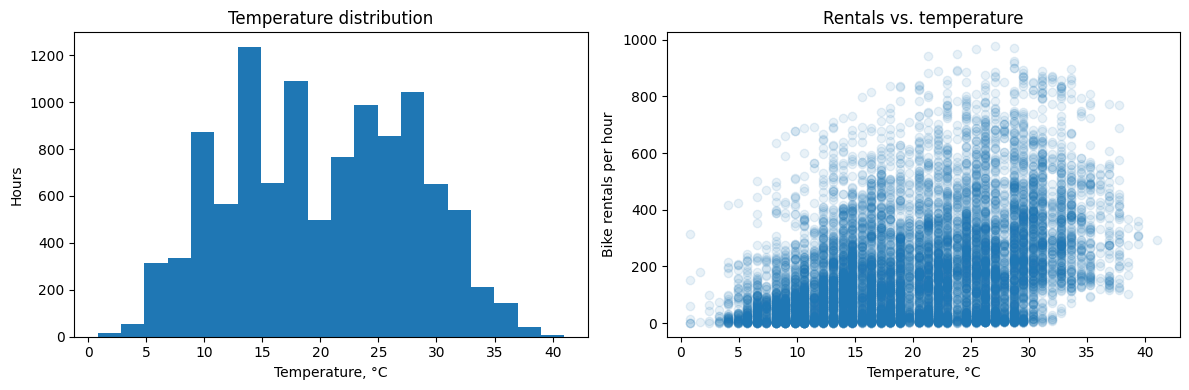

In [61]:
figure, axis = plt.subplots(1, 2, figsize=(12, 4))

# 1.
axis[0].hist(bikes_known["temp"], bins=20)
axis[0].set_title("Temperature distribution")
axis[0].set_xlabel("Temperature, " + deg + "C")
axis[0].set_ylabel("Hours")

# 2.
axis[1].scatter(bikes_known["temp"], bikes_known["count"], alpha=0.1)
axis[1].set_title("Rentals vs. temperature")
axis[1].set_xlabel("Temperature, " + deg + "C")
axis[1].set_ylabel("Bike rentals per hour")

# 3.  -> left: temperatures are spread 0-40 °C with two humps (winter / summer);
#        right: rentals rise with temperature up to ~30 °C, with a very wide spread at every temperature
figure.tight_layout()
plt.show()

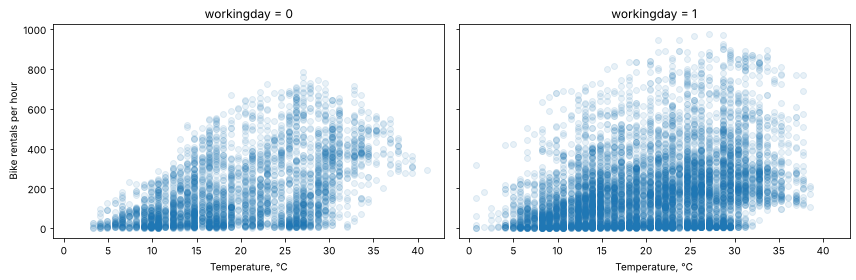

In [ ]:
# optional
figure, axis = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for i, wd in enumerate([0, 1]):
    rows = bikes_known["workingday"] == wd
    axis[i].scatter(bikes_known.loc[rows, "temp"], bikes_known.loc[rows, "count"], alpha=0.1)
    axis[i].set_title(f"workingday = {wd}")
    axis[i].set_xlabel("Temperature, " + deg + "C")
axis[0].set_ylabel("Bike rentals per hour")
figure.tight_layout()
plt.show()

## Seaborn

Seaborn is a data visualization library __based on matplotlib__ that provides a high-level interface for drawing attractive and informative statistical graphics.

Key advantages:
1. Attractive and easily manageable themes
2. Usable statistical plots

seaborn's idea:
* you name the **DataFrame** and the **columns** (`data=`, `x=`, `y=`), and say which column should become **colour** (`hue=`) or **panels** (`col=`, `row=`) - seaborn does the grouping, the loop over colours and the legend that we wrote by hand with matplotlib above.
* It is installed in Colab (`import seaborn as sns`; `sns` is the conventional name).

In [62]:
import seaborn as sns

## Themes: Accent palette

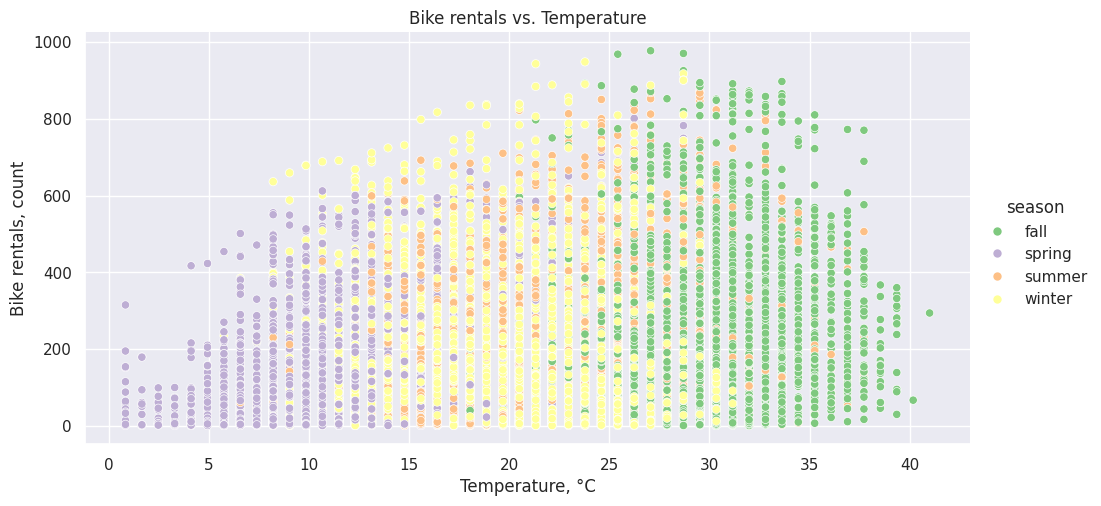

In [63]:
sns.set(rc={'figure.dpi':100, 'figure.figsize':(6,4)})
sns.set(style="darkgrid", palette="Accent")
ax = sns.relplot(data = bikes, x='temp', y='count', kind="scatter", hue="season", aspect=2)
ax.set(xlabel = "Temperature, "+deg+"C", ylabel = 'Bike rentals, count', title="Bike rentals vs. Temperature");

## Themes: Colorblind palette

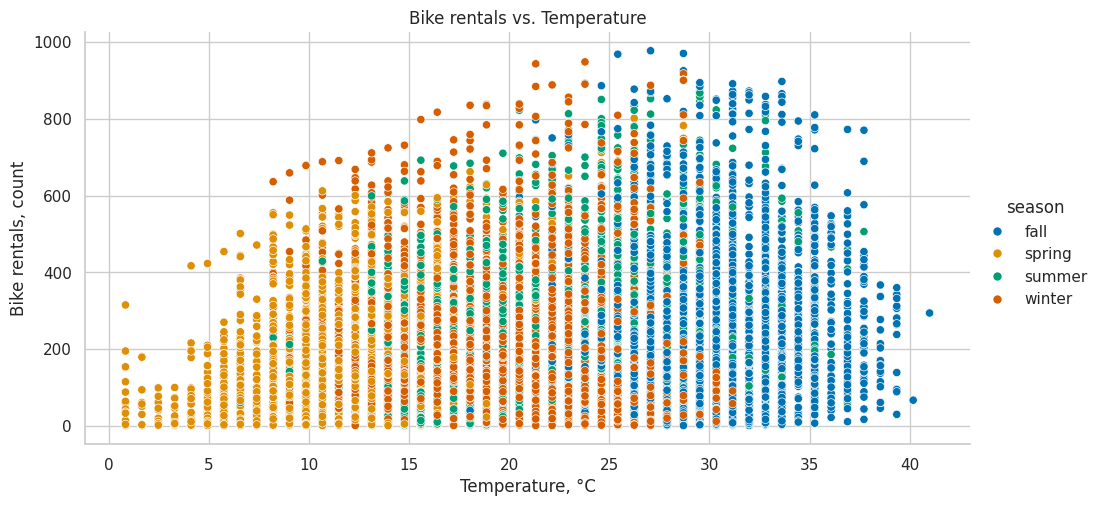

In [64]:
sns.set(style="whitegrid", palette="colorblind")
ax = sns.relplot(data = bikes, x='temp', y='count', kind="scatter", hue="season", aspect=2)
ax.set(xlabel = "Temperature, "+deg+"C", ylabel = 'Bike rentals, count', title="Bike rentals vs. Temperature");

About 8 % of men cannot tell red from green. The `colorblind` palette is readable for everyone and is a sensible default for anything you publish - principle 1, *focus on your audience*. `whitegrid` is the usual theme for printed reports.

## Advanced plots: Histogram + Density

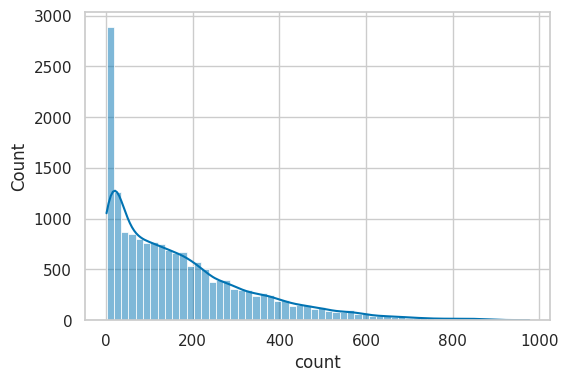

In [65]:
sns.histplot(data=bikes, x='count', kde=True);

Histogram and density curve in one call (`kde=True` - kernel density estimate; the counts are the truth, the curve is the smoothed guide). `histplot` is *axes-level* - it returns a matplotlib Axes, so `set_title` / `set_xlabel` work directly on it. Add `hue="season"` to get one coloured histogram per season.

## Advanced plots: Violin plot

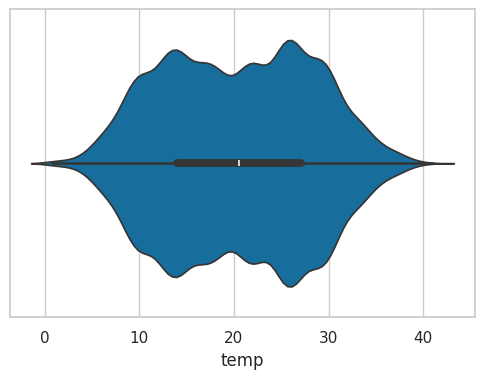

In [68]:
sns.violinplot(data=bikes, x='temp');

## Advanced plots: Violin plot

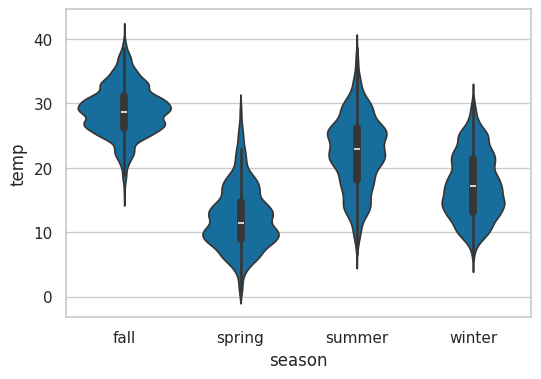

In [69]:
sns.violinplot(data=bikes, y='temp', x='season');

A **violin** is a box plot (the thin bar and white dot in the middle: quartiles and median) with a density curve drawn on both sides - you see the summary *and* the shape. `x='season', y='temp'` → one violin per category: spring (Jan-Mar) is cold and wide, summer and fall are warm and narrow. This is *the* plot for "how does a numeric value differ between groups".

### Preparing a two-way table for a heatmap

The next plot needs a table with **two categories × one value**: median rentals for every weekday × hour. Pure 5.2 - `groupby` with two keys, then `pivot` to a wide table (Dmitry builds it for his 3D plots, which are in the appendix):

In [70]:
bikes_3D = bikes.groupby([bikes['datetime'].dt.weekday,bikes['datetime'].dt.hour]).agg({'count':'median'})
bikes_3D.index.names = ["weekday","hour"]
bikes_3D = bikes_3D.reset_index().pivot(index=['hour'],columns=['weekday'], values='count').astype(float)
bikes_3D.T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
0,30.0,13.0,8.0,4.0,5.0,23.0,94.0,268.0,417.0,219.0,...,185.0,196.0,298.0,528.0,518.0,372.0,240.0,177.0,116.0,63.0
1,26.0,11.0,5.0,3.0,5.0,22.0,108.5,311.5,462.5,219.5,...,159.0,178.0,292.0,569.0,538.0,365.0,268.0,195.0,137.0,73.0
2,33.0,12.0,5.0,4.0,4.0,27.0,112.0,312.0,487.0,225.0,...,163.0,176.0,277.0,517.0,489.0,347.0,256.0,189.0,129.0,70.0
3,34.0,15.0,7.0,4.0,5.0,26.0,112.0,304.0,484.0,227.0,...,180.0,180.0,294.0,563.0,523.0,364.0,258.0,195.0,149.0,97.0
4,54.5,23.0,11.0,6.0,5.0,24.0,87.5,248.0,454.0,244.5,...,215.5,233.5,338.5,510.5,424.0,293.0,215.5,164.5,148.5,119.5
5,95.0,70.5,51.0,23.0,7.0,8.0,20.5,46.5,118.5,207.0,...,389.0,393.5,399.0,347.0,297.0,248.0,181.5,165.0,146.5,124.0
6,99.5,77.5,66.0,28.0,9.5,8.0,15.0,34.5,87.0,169.0,...,355.0,356.5,353.0,326.0,254.5,227.5,175.0,132.0,95.5,54.5


## Advanced plots: Heatmap

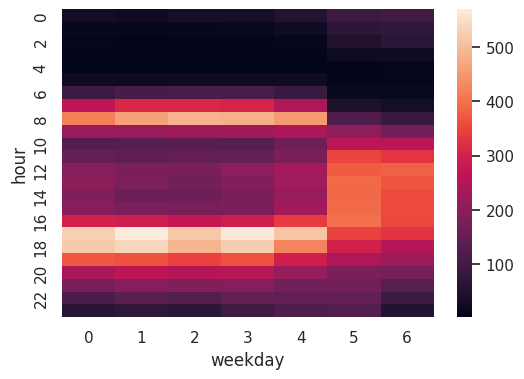

In [71]:
sns.heatmap(bikes_3D);

Colour = value in each hour × weekday cell: two bright bands at 8 and 17-18 on weekdays 0-4 (Mon-Fri commute), one broad bright area around midday on 5-6 (weekend leisure). A heatmap shows a whole 7 × 24 table in one glance - and is far easier to read than the 3D surface of the same data in the appendix.

## Advanced plots: Heatmap for correlation matrix

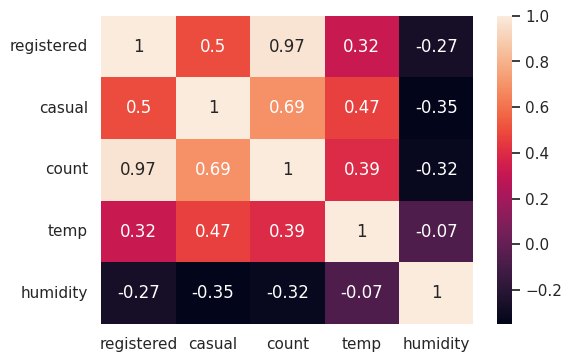

In [72]:
sns.heatmap(bikes[['registered','casual','count','temp','humidity']].corr(), annot=True);

The **correlation matrix** from 5.1 as a heatmap, numbers written in (`annot=True`). Read it carefully: `count` vs `registered` = 0.97 is **not a discovery** - `count` is *defined* as `casual + registered`, so the correlation is there by construction; for the project choose columns that are not built from each other. The informative cells are the weather ones: `casual` riders show the strongest linear association with temperature (0.47), `registered` a weaker one (0.32); humidity is negative for both. "Strongest linear association" is the right wording - not "matters most": correlation measures one kind of relationship only (5.1).

## Advanced plots: Lines instead of Scatters

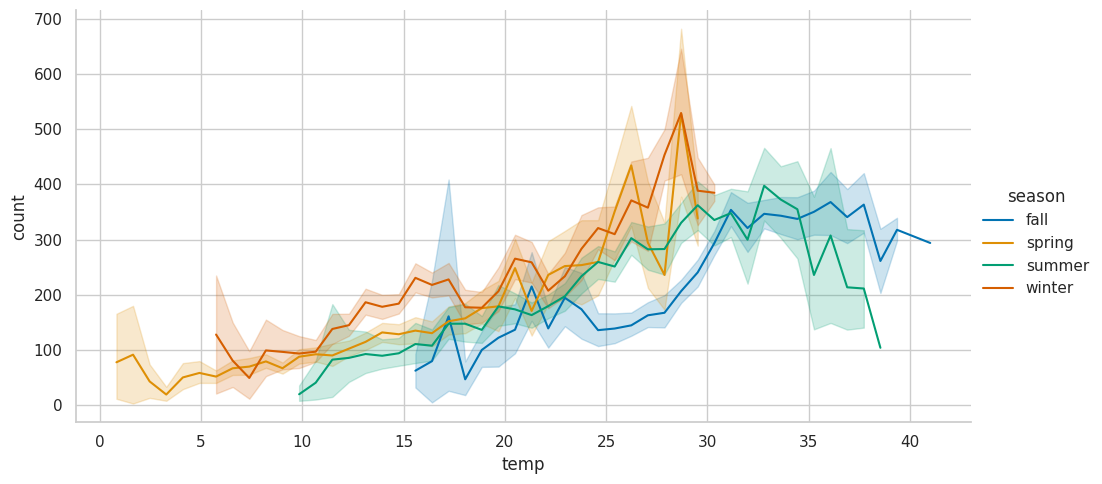

In [73]:
sns.relplot(data = bikes.dropna(), x='temp', y='count', kind="line", hue="season", aspect=2);

`kind="line"` with many y values per x: seaborn draws the **mean** rentals per temperature value as a line and a shaded band that shows the **estimation uncertainty** of that mean, under the plotting method's assumptions (hourly observations of the same days and seasons are not independent, so the band is optimistic - read it as "roughly how sure", not as a statistical test). `dropna()` removes the test rows without `count`. Rentals grow with temperature up to about 30-35 °C and fall above - the scatter only hinted at that.

## Advanced plots: Linear regression

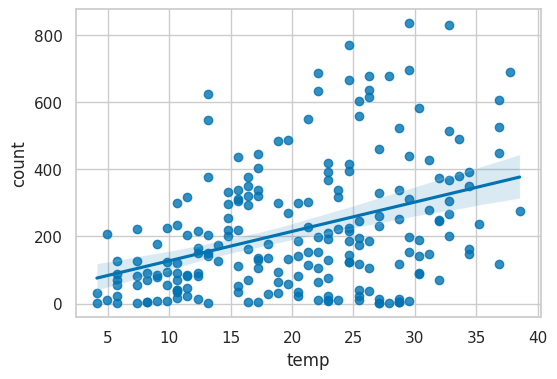

In [74]:
bikes_sample = bikes.sample(300)
sns.regplot(data=bikes_sample, x='temp', y='count');

## Advanced plots: Linear regression

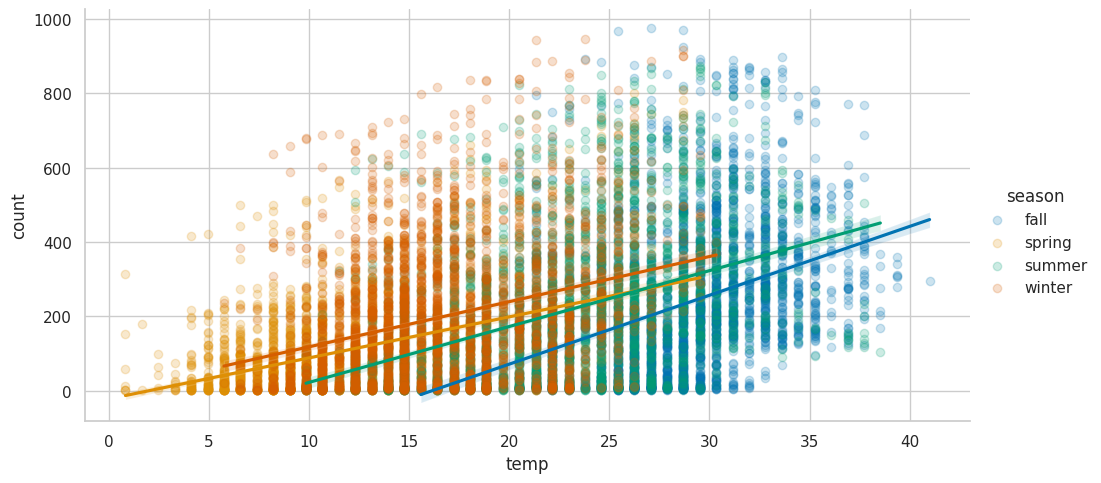

In [75]:
sns.lmplot(data=bikes, x='temp', y='count', hue="season",aspect=2,  scatter_kws={'alpha':0.2});

`regplot` adds the best-fitting straight line (and its uncertainty band) to a scatter - a preview of block 8, *modelling*; here a short demonstration. `lmplot` does it per group: one line per season, and the slopes differ (steep in spring, flat in summer) - a first hint that one straight line for all data is too simple. `sample(300)` draws 300 random rows so that the points stay visible (rows without `count` are dropped automatically). Remember 5.1: a line through a cloud shows *association*, not cause.

## Advanced plots: Facet grid

*Optional* - the pay-off of 5.2 `melt`: seaborn wants **long** data - one column (`variable`) saying *which* measure a row is, one column (`value`) with the number. Then `FacetGrid(col='season', row='variable')` draws a 3 × 4 grid of histograms - twelve panels, four lines of code.

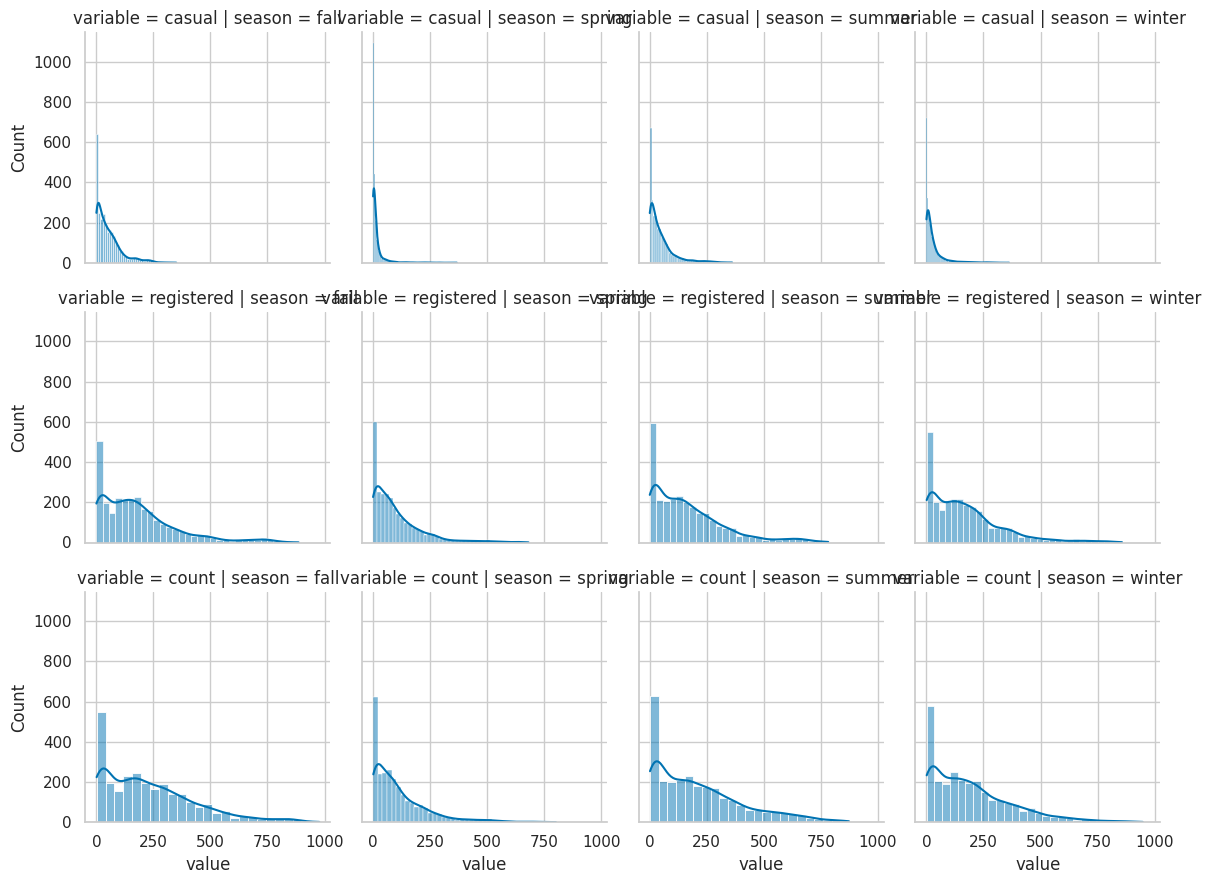

In [76]:
bikes_long = bikes.melt(id_vars=['season'],value_vars=["casual","registered", "count"])
g = sns.FacetGrid(bikes_long, col='season', row='variable').map(sns.histplot, 'value', kde=True)

Rows: casual riders peak at very small numbers in every season; registered and total rentals spread much further. (`g` is a FacetGrid: titles for all panels at once with `g.set_titles(...)`, axis labels with `g.set_axis_labels(...)`.)

### YOUR TURN 3: seaborn

Use `bikes_known` for anything with rentals.

1. `sns.histplot` of `temp` with `hue="season"` and `kde=True` (on `bikes` - temperature is known for all hours). Which season has the widest range of temperatures?
2. `sns.violinplot` of `count` (y) by `workingday` (x). Where is the difference - in the median, or in the shape?
3. A correlation heatmap (`annot=True`) of `temp`, `humidity`, `windspeed`, `casual`, `registered` (no `count` - it is the sum of the last two). Which weather variable shows the strongest linear association with *casual* rentals, which with *registered*?
4. Write one sentence of insight for each of the three figures - as you would under a figure in the project report.

*Optional:* `sns.relplot(..., kind="line", x="hour", y="count", hue="workingday")` after creating `bikes_known["hour"] = bikes_known["datetime"].dt.hour` - what differs between working days and free days?

In [ ]:
# YOUR CODE HERE:

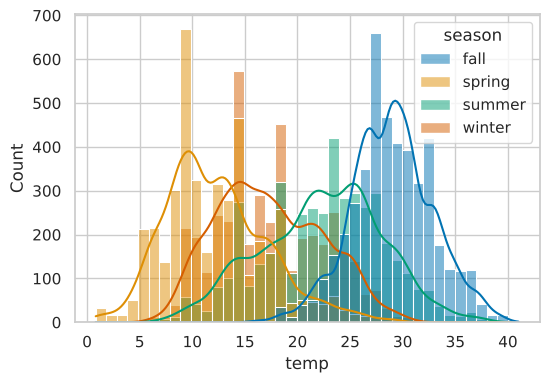

In [ ]:
# 1.  -> spring (Jan-Mar in this data set) spans ~0-30 °C; summer and fall are narrow and warm
sns.histplot(data=bikes, x="temp", hue="season", kde=True);

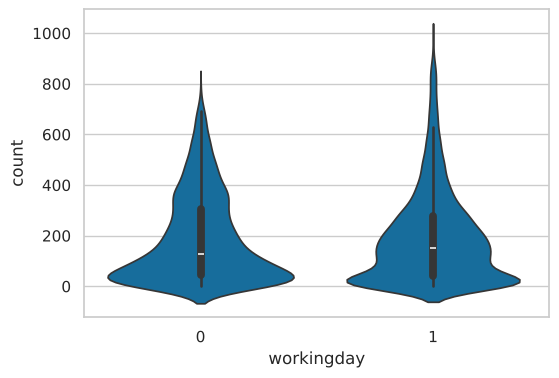

In [ ]:
# 2.  -> medians are similar; the SHAPE differs: working days have a long thin tail of very busy (commute) hours
sns.violinplot(data=bikes_known, x="workingday", y="count");

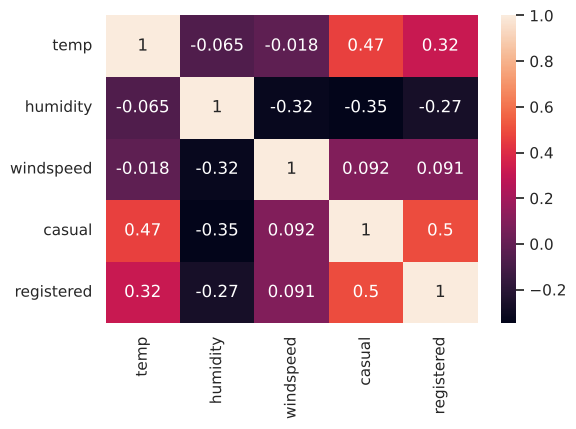

In [ ]:
# 3.  -> casual: temperature (0.47) is the strongest linear association; registered: temperature too (0.32) but weaker,
#        humidity negative for both; windspeed hardly matters
sns.heatmap(bikes_known[["temp", "humidity", "windspeed", "casual", "registered"]].corr(), annot=True);

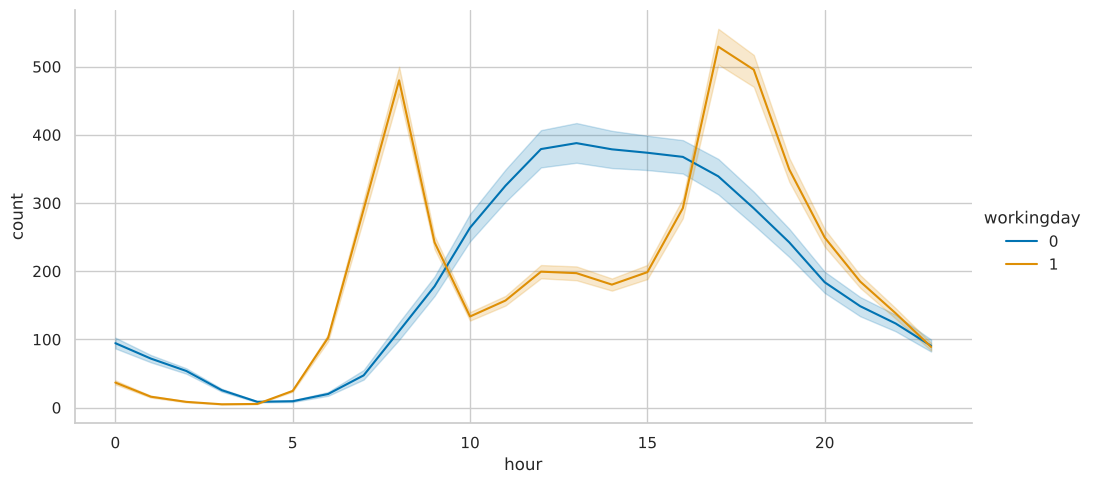

In [ ]:
# optional -> two commute peaks on working days, one broad afternoon hump on free days
bikes_known = bikes_known.copy()
bikes_known["hour"] = bikes_known["datetime"].dt.hour
sns.relplot(data=bikes_known, x="hour", y="count", kind="line", hue="workingday", aspect=2);

## Summary

* choose the plot from the **question**: distribution → histogram / density / box; relationship → scatter (+ regression); categories → bar (pie only for shares of a whole); time → line / area; two categories × value → heatmap
* **data first**: fix the dtypes (`category`, `datetime`), know how many rows a chart uses and what was dropped (`NaN`) - `bikes_known` vs `bikes`
* **pandas**: `s.plot.hist(bins=)`, `df.plot.box()`, `df.plot.scatter(x=, y=, alpha=)`, `groupby().agg().plot.bar()`, `set_index("datetime")[col].plot.line()`, `.plot.area()`
* **matplotlib**: `figure, axis = plt.subplots(rows, cols, figsize=, sharex=, sharey=)`; `axis[i]` / `axis.flatten()`; draw with `axis.scatter / hist / plot` or pandas `ax=axis[i]`; finish with `set_title`, `set_xlabel`, `set_ylabel` (units!), `legend`, `figure.tight_layout()`; bars start at 0
* **seaborn**: `sns.set(style=, palette="colorblind")`; `relplot(data=, x=, y=, hue=, kind=)` (figure-level → grid, `.set()`), `histplot(kde=True)`, `violinplot(x=category, y=value)`, `heatmap(table or corr(), annot=True)` (axes-level → Axes), `regplot` / `lmplot`
* **reading charts honestly**: correlation = linear association, not cause; `count = casual + registered` correlates by construction; bands show estimation uncertainty under assumptions
* for the **project**: explore with pandas, present with seaborn / a matplotlib grid, every figure = title + labelled axes + number of observations + one sentence of insight

# Thank you

### 3D plots

(The table `bikes_3D` - median rentals per weekday × hour - was built in the seaborn section.)

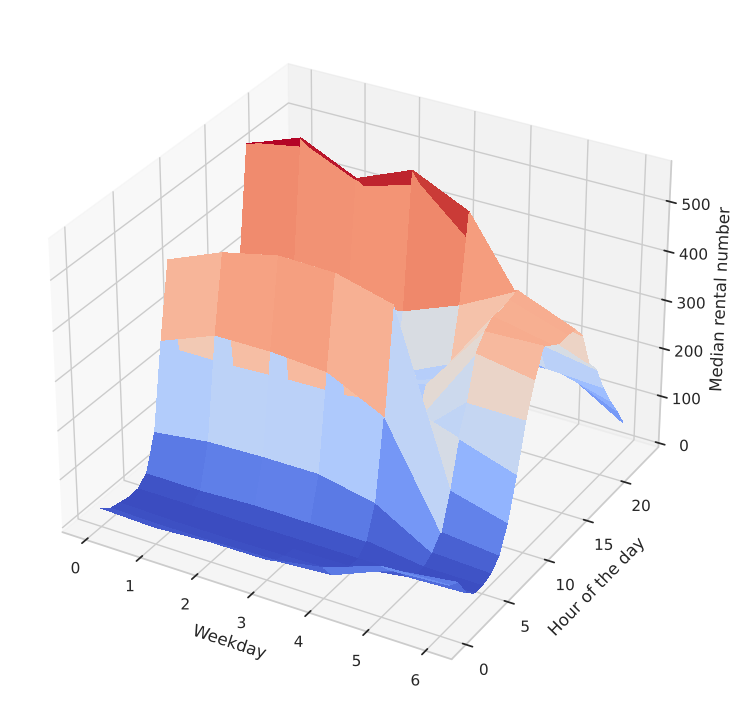

In [ ]:
figure, axis = plt.subplots(subplot_kw={"projection": "3d"},figsize=(9,9))
X, Y = np.meshgrid(bikes_3D.columns, bikes_3D.index)
surf = axis.plot_surface(X, Y, bikes_3D, cmap=plt.cm.coolwarm, linewidth=0, antialiased=False)
axis.set_ylabel("Hour of the day")
axis.set_xlabel("Weekday")
axis.set_zlabel("Median rental number")
plt.show()

### 3D plots: Formatter

In [ ]:
import calendar
list(calendar.day_abbr)

['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

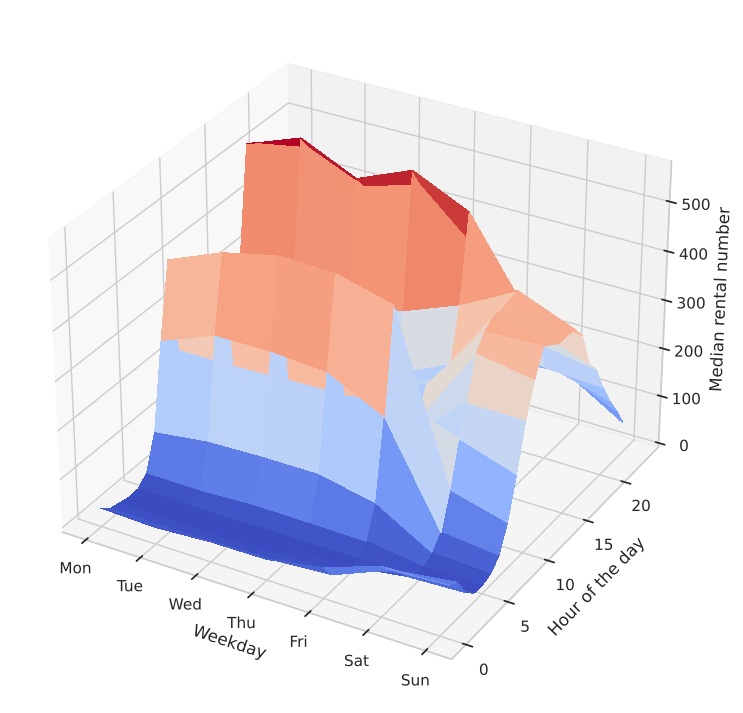

In [ ]:
def format_days(x, pos):
    if (int(x) in range(len(calendar.day_abbr))):
        return(calendar.day_abbr[int(x)])

figure, axis = plt.subplots(subplot_kw={"projection": "3d"},figsize=(9,9))
X, Y = np.meshgrid(bikes_3D.columns, bikes_3D.index)
surf = axis.plot_surface(X, Y, bikes_3D, cmap=plt.cm.coolwarm, linewidth=0, antialiased=False)
axis.set_ylabel("Hour of the day")
axis.set_xlabel("Weekday")
axis.xaxis.set_major_formatter(plt.FuncFormatter(format_days))
axis.set_zlabel("Median rental number")
plt.show()

The surface shows the weekly rhythm: two sharp ridges at 8 and 17-18 on Monday-Friday (commuting), one broad hump around midday on Saturday-Sunday (leisure). `format_days` is a function (week 3) that turns the weekday number 0-6 into "Mon" ... "Sun" for the tick labels. Impressive - but 3D plots are hard to read exactly; the seaborn heatmap of the same table in the main part is the version for a report.

### 3D plots: contours and heatmaps

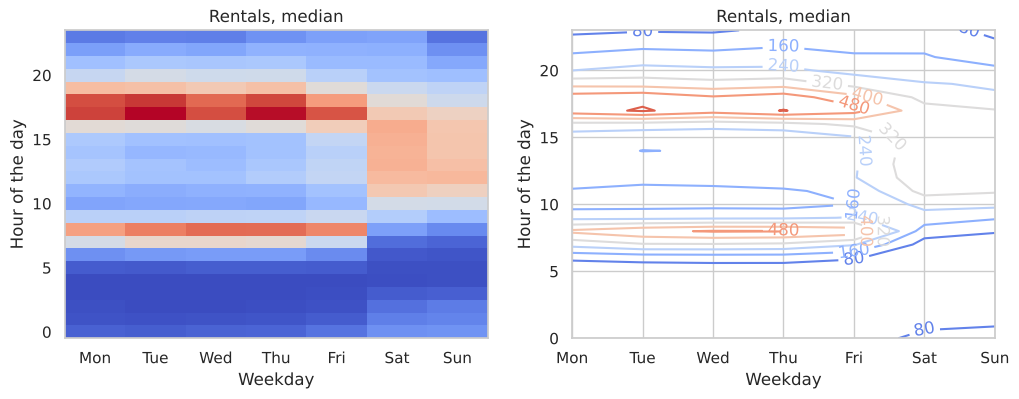

In [ ]:
figure, axis = plt.subplots(1,2, figsize=(12,4))
X, Y = np.meshgrid(bikes_3D.columns, bikes_3D.index)
axis[0].grid(False)
axis[0].pcolormesh(X, Y, bikes_3D, cmap=plt.cm.coolwarm)
axis[0].set_title("Rentals, median")
axis[0].set_ylabel("Hour of the day")
axis[0].set_xlabel("Weekday")
axis[0].xaxis.set_major_formatter(plt.FuncFormatter(format_days))
cs = axis[1].contour(X, Y, bikes_3D, cmap=plt.cm.coolwarm)
plt.clabel(cs, inline=1)
axis[1].set_title("Rentals, median")
axis[1].set_ylabel("Hour of the day")
axis[1].set_xlabel("Weekday")
axis[1].xaxis.set_major_formatter(plt.FuncFormatter(format_days))
plt.show()

A **heatmap** drawn with plain matplotlib (`pcolormesh`) and **contour lines** (lines of equal rentals, like heights on a map) - the same information as the 3D surface, flat and comparable. Rule of thumb: prefer the flat version; use 3D only when it adds something.